# Traffic signs and road in one pass

One network that detects traffic signs and segments the road in a single forward pass, trained and evaluated on Virtual KITTI.

- **Author:** Hussein Loubani
- **Dataset:** Virtual KITTI 1.3.1 (Gaidon et al. 2016), the Dataset Ninja copy the brief links to: 21,260 RGB frames of 1242 x 375 pixels from five driving videos rebuilt in the Unity game engine, each video rendered ten ways, with a class for every pixel
- **Targets:** a box around every traffic sign, and the road as a mask over the frame
- **Task:** multi-task learning, object detection and semantic segmentation from one shared backbone with two heads, fine-tuned from COCO weights
- **Primary metrics:** sign AP50 (COCO average precision at an IoU of 0.5) and road IoU on the test world; COCO mAP, AP by sign size, mean IoU, pixel accuracy and latency are secondary

### Table of contents

1. [Imports and setup](#1.-Imports-and-setup)
2. [Problem definition](#2.-Problem-definition)
3. [Data download and first audit](#3.-Data-download-and-first-audit)
4. [Data cleaning](#4.-Data-cleaning)
5. [Partitions](#5.-Partitions)
6. [Exploratory data analysis](#6.-Exploratory-data-analysis)
7. [The multi-task network](#7.-The-multi-task-network)
8. [Training](#8.-Training)
9. [How much is left in the recipe](#9.-How-much-is-left-in-the-recipe)
10. [Final evaluation on the test world](#10.-Final-evaluation-on-the-test-world)
11. [Best and worst frames](#11.-Best-and-worst-frames)
12. [Conclusion, limitations and recommendations](#12.-Conclusion,-limitations-and-recommendations)

## 1. Imports and setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from driving_scenes.config import (
    ANCHOR_CANDIDATES,
    ANCHOR_IOU_LEVELS,
    BASELINE_VARIANTS,
    CANDIDATE_VARIANTS,
    CEILING_FRAMES,
    COCO_ANCHOR_PREFIX,
    DISPLAY_PRECISION,
    EXTREME_COUNT,
    FINETUNE_STAGES,
    FRAME_HEIGHT,
    FRAME_WIDTH,
    IGNORE_LABEL,
    PARTITIONS,
    PREDICTION_DIR,
    RANDOM_SEED,
    RENDERING_STEPS,
    REPETITION_LAGS,
    REPETITION_VARIATION,
    ROAD_CALL_DIR,
    ROAD_THRESHOLD,
    SAME_SIGN_IOU,
    SEEDS,
    VARIATIONS,
    WORST_SHARE,
)
from driving_scenes.dataset import (
    BOX_COLUMNS,
    ROAD_INDEX,
    assign_partitions,
    audit_summary,
    boxes_by_frame,
    build_index,
    frame_table,
    one_rendering_per_step,
    write_processed,
)
from driving_scenes.download import download_virtual_kitti
from driving_scenes.exploration import (
    anchor_coverage,
    best_anchor_iou,
    box_heatmap,
    class_frequency,
    class_shares,
    coarse_mask_ceilings,
    describe_signs,
    frame_repetition,
    group_summary,
    has_close_neighbor,
    rendering_agreement,
    rendering_examples,
    sign_examples,
    sign_summary,
    world_examples,
)
from driving_scenes.modeling.evaluate import (
    cached_predictions,
    cached_road_calls,
    compare_runs,
    detection_reliability,
    device,
    extreme_frames,
    fixed_mask_counts,
    frame_scores,
    frame_titles,
    prediction_panels,
    recall_by,
    score_predictions,
    scores_by_group,
    sign_outcomes,
    size_scores,
    threshold_sweep,
    time_per_frame,
    timing_images,
)
from driving_scenes.modeling.experiments import (
    carried_forward,
    held_out_predictions,
    split_frames,
    train_recipe,
    train_seeds,
    train_variant,
    variant_verdicts,
)
from driving_scenes.modeling.metrics import road_scores
from driving_scenes.modeling.model import build_model, parameter_counts
from driving_scenes.modeling.train import best_epoch, load_model, read_history, read_pulls
from driving_scenes.plots import (
    apply_style,
    frame_panels,
    plot_anchor_coverage,
    plot_class_shares,
    plot_group_scores,
    plot_heatmaps,
    plot_history,
    plot_mask_ceiling,
    plot_pulls,
    plot_reliability,
    plot_rendering_light,
    plot_repetition,
    plot_road_calls,
    plot_runs,
    plot_sign_shapes,
    plot_size_scores,
    plot_threshold_sweep,
    save_figure,
    truth_panels,
)

In [2]:
apply_style()
pd.set_option("display.float_format", lambda value: f"{value:.{DISPLAY_PRECISION}f}")
print(f"PyTorch {torch.__version__}, computing on {device()}")

PyTorch 2.13.0+cu126, computing on cuda


All logic lives in the `driving_scenes` package under `src/`, installed in editable mode, and every constant is in `config.py`; the notebook calls functions and interprets what they return. Expensive results (the decoded labels, every trained network and every set of predictions) are cached on disk the first time they are computed, each with a fingerprint of everything that produced it: the frames and their labels, the starting weights, every setting and the seed. A rerun therefore repeats the whole analysis in minutes, and a change to any of those inputs recomputes the result instead of reloading a stale one under the same name. The training curves of the cached runs are read back from their logs. Every network in this notebook was trained on one machine, an NVIDIA RTX 3090 with PyTorch 2.13 and CUDA 12.6, so their training times and scores compare like for like.

## 2. Problem definition

**The situation:** a car's camera delivers a frame many times per second, and the software has to answer several questions about each one at once: where the road is, where the signs are, where the other vehicles are. One network per question repeats the expensive part, turning pixels into features, once per question. Tesla's HydraNets, which the brief points to, share one backbone between many task heads, so the frame is described once and every head reads that description (Karpathy 2019). This project builds the two-task version the brief asks for: one network that, in a single forward pass, puts a box around every traffic sign and marks every road pixel.

**Why one network and not two:** a shared backbone saves computation at inference, which section 10 measures, and the two tasks can help or hurt each other through what each teaches the shared features. Which of the two happens is an empirical question, so the project also trains a signs-only and a road-only network with the same recipe and compares them with the two-headed one.

### Two kinds of output: boxes and masks

**Detection** finds countable objects, "things", and returns a box, a class and a confidence for each one. **Segmentation** classifies pixels, and comes in three kinds:

- **Semantic segmentation** gives every pixel a class and does not tell two objects of one class apart: two cars side by side become one "car" region. It suits "stuff", amorphous regions such as road, sky or vegetation that have no instances to count.
- **Instance segmentation** draws a separate mask for each object, so two adjacent cars get two masks. It only makes sense for countable things, and Mask R-CNN (He et al. 2017) does it by predicting a small mask inside each detected box.
- **Panoptic segmentation** (Kirillov et al. 2019) combines the two: every pixel gets a class, and the pixels of countable classes also get an instance id.

The road is stuff: one region with no instances to separate, which often runs from the bottom edge of the frame to the horizon, so it is a semantic segmentation target. Signs are things, and the brief asks for a box per sign, which is detection.

### How a detector finds objects

**Two-stage detectors** such as Faster R-CNN (Ren et al. 2015) first propose and then classify. The **region proposal network (RPN)** slides a small convolution over the feature maps, and at every position it scores a fixed set of reference boxes, the **anchors**, which come in several sizes and height-to-width ratios. For each anchor it predicts two things: the probability that the anchor covers an object of any class, and four numbers that shift and stretch the anchor onto that object. The purpose of the RPN is to cut the search from the hundreds of thousands of anchors in a frame down to a few hundred proposals that probably contain an object, using the same features the second stage reads afterwards, so the proposals cost almost nothing extra. The second stage crops each proposal's features from the feature map with RoIAlign, classifies the crop and refines its box once more.

**SSD** (Liu et al. 2016) does it in one stage. Default boxes, SSD's name for anchors, sit at every position of several feature maps of decreasing resolution, and for every default box the network predicts class scores and box offsets directly. In training, every true box is matched to the default boxes it overlaps by an IoU above 0.5, which become positives for its class, and the rest become background. Anchors improve detection in three ways: they turn an open-ended regression ("where is a box?") into a classification plus a small correction to a known prior box, they let one position predict several objects of different shapes, and they hand each object to the feature map whose resolution suits its size.

**YOLO** (Redmon et al. 2016) also detects in one pass. It divides the image into an S x S grid, and the cell that contains an object's center is responsible for that object: each cell predicts a few boxes with a confidence each, plus class probabilities. Several objects in one image are handled by different cells at the same time, and non-maximum suppression removes duplicate boxes for one object. Because the original YOLO lets each cell predict only a couple of boxes, small objects close together are its weak point, which later versions address with anchors and predictions at several scales.

**Why Faster R-CNN here:** signs are small and tall (section 6 shows that nearly half are under 32 x 32 pixels), and the two-stage design gives every proposal a second, closer look at the pyramid level that suits its size. torchvision provides it with COCO weights on a ResNet-50 with a feature pyramid network (FPN), the backbone of the Mask R-CNN the brief suggests. The Mask R-CNN mask head itself is left out, because the signs need boxes only and the road needs a per-pixel head, a choice section 6 tests.

### How the results are measured

- **IoU (intersection over union)** is the area two regions share divided by the area they cover together, for one predicted region against one true region, boxes or masks alike. It is 1 for a perfect fit and 0 for no overlap.
- **Average precision (AP)** scores a detector's whole output. A detection is a hit when its IoU with a sign reaches a threshold, 0.5 for **AP50**, and no more confident detection has already taken that sign. Ranking all detections over all frames by confidence and walking down the list traces precision (the share of detections so far that hit) against recall (the share of signs found so far), and AP is the area under that curve. COCO's **mAP** averages AP over ten IoU thresholds from 0.5 to 0.95, so it also rewards tight boxes; with a single class, the "mean" runs over the thresholds only.
- **IoU against mAP:** IoU judges the fit of one box to one sign, so it measures localization. mAP judges the ranked list, so it measures whether the detector finds the signs, how many false alarms it ranks among them, and, through the stricter thresholds, how well its boxes fit. A detector can draw perfect boxes around the signs it finds and still have a low AP because it misses half of them, or find every sign with loose boxes and score a high AP50 with a low mAP. In this project IoU is also the threshold inside AP that decides what counts as a hit.
- **Road IoU** counts every labeled pixel as a true or false positive or negative: road IoU = TP / (TP + FP + FN). **Pixel accuracy** counts the true negatives as well, and since about three quarters of a frame is not road, a network that calls nothing road scores about 0.75 pixel accuracy with a road IoU of 0. Road IoU is the primary road score; the **mean IoU** of road and not-road and the pixel accuracy are reported for comparison with the segmentation literature.

### What "penalize both tasks equally" means

The network minimizes a sum of five loss terms. Four belong to the detector: the RPN's binary cross-entropy on "does this anchor cover a sign" and its smooth L1 loss on the anchor's shift, then the box head's cross-entropy over sign and background and its smooth L1 loss on the refined box. One belongs to the road: binary cross-entropy per pixel, averaged over the labeled pixels. Weighting the two tasks one to one makes them count equally in the number being minimized, but the shared backbone does not see the losses; it sees their gradients, and two tasks' gradients at the shared features can differ by an order of magnitude whatever their loss values. The task with the larger gradient then decides where the shared weights move.

The trainer therefore measures each task's **pull** on the shared features, the norm of its loss gradient at the outputs of the feature pyramid, and in its "equal" mode it rescales each task's gradient on the way into the backbone so that both arrive with the same norm, a simple form of the gradient normalization of Chen et al. (2018). Each head still learns from its own unscaled loss. Section 8 shows the pulls during training, and section 9 tests whether the balancing matters by training the plain sum of the losses as a variant.

### Where the brief's requirements are met

| Requirement of the brief | Section |
|---|---|
| Download Virtual KITTI, RGB frames with their detection and segmentation labels | 3 |
| EDA on the images | 4 and 6 |
| Training, validation and test sets with no video in two partitions | 5 |
| A pretrained architecture suited to detection and segmentation | 7 |
| Two heads, one for the road and one for the signs, with losses that penalize both tasks equally | 7 to 9 |
| Fine-tune the backbone | 8 |
| Evaluate both tasks | 10 |
| Examine the best and worst samples | 11 |

## 3. Data download and first audit

The brief links the Dataset Ninja copy of Virtual KITTI 1.3.1, a single 29.5 GB tar in Supervisely format. It holds three renderings of every frame (RGB, depth and optical flow), each with its own copy of the same annotation file, and the brief asks for the RGB frames and their labels. `download_virtual_kitti` streams the archive from its HTTP response, keeps the RGB frames, their annotation files and the class list, skips everything else as it passes, and resumes at the last complete file after a dropped connection. A later call only counts the files.

In [3]:
download_virtual_kitti()

{'img': 21260, 'ann': 21260}

**Every RGB frame and its annotation file is on disk:** 21,260 of each, every moment of the five worlds shown in ten renderings.

An annotation file describes a frame as a list of objects, each one connected region of one class stored as a small bitmap with the position of its corner. The index decodes every frame in full, which doubles as the integrity check of the download, and every annotation's bitmaps into a label map per frame: the class of every pixel, or 255 where the archive gives no label. The two targets come out of those maps. The road mask is the union of the road regions, and a sign box is the extent of one traffic-sign region, because the archive draws boxes only around vehicles. The label maps are cached, so the network's data loader reads one small PNG per frame instead of decoding about 150 bitmaps.

In [4]:
frames, signs = build_index(frame_table())
audit_summary(frames, signs).to_frame("value")

,value
frames,21260
worlds,5
renderings per world,10
frame sizes (width x height),1242 x 375
frames whose label map has another size,0
frames whose tags disagree with their name,0
pixels claimed by two regions,0
frames with every pixel labeled,0
percent of pixels without a label,0.380
labeled pixels accounted for,True


**The download is complete and consistent, and every frame decodes:** all 21,260 frames are 1242 x 375 pixels, every label map has its frame's size, every file's tags (world and rendering) agree with its name, and no pixel is claimed by two regions, so the labeled pixels and the unlabeled ones add up to each frame exactly. No frame is fully labeled, though: 0.380% of all pixels carry no class, which the next section locates. The frames hold 52,367 traffic-sign regions, and the smallest the archive kept has 51 pixels.

In [5]:
group_summary(frames, "world")

,moments,share of moments,frames,renderings,signs per frame,frames with a sign,road share
world,,,,,,,
0001,447,0.210,4470,10,1.194,0.601,0.232
0002,233,0.110,2330,10,0.952,0.887,0.311
0006,270,0.127,2700,10,6.480,0.994,0.403
0018,339,0.159,3390,10,1.084,0.806,0.192
0020,837,0.394,8370,10,2.824,0.843,0.195


**The five worlds differ far more than their names suggest:** world 0020 alone holds 39.4% of the moments (837) and world 0002 only 11.0% (233). Signs are rare in 0002 and 0018, about one per frame, and dense in 0006, with 6.48 per frame and a sign in 99.4% of its frames. The road covers 40.3% of the picture in 0006 but 19.2% in 0018 and 19.5% in 0020. Which worlds go to training therefore decides what the network sees most, and section 5 has to split them with that in mind.

## 4. Data cleaning

### Pixels without a label

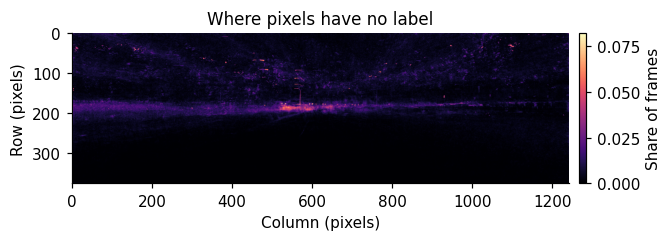

In [6]:
moments = one_rendering_per_step(frames)
unlabeled = class_frequency(moments, IGNORE_LABEL)
fig = plot_heatmaps({"Where pixels have no label": (unlabeled, "Share of frames")})
save_figure(fig, "unlabeled_pixels", "cleaning")
plt.show()

**What has no label is far away:** the unlabeled pixels gather along the horizon, most densely around the vanishing point near the middle of the frame, with a sparse scatter in the upper half where thin poles and branches stand against the sky. No single pixel is unlabeled in more than about 8% of the frames (the top of the color scale). That fits the 51-pixel floor seen above: the converter that produced this copy dropped regions smaller than that, which are distant objects. **Decision:** these pixels keep the value 255, which the road loss and every road score skip, so they count neither for nor against the network. No frame is removed for them, since every frame has a few.

### What a sign region is

A traffic-sign region in this copy is one connected component of sign pixels, so the dataset has no notion of a sign instance: a sign split in two by a branch in front of it becomes two regions, and so do two signs mounted on one post if their pixels do not touch. The table describes all 52,367 regions, and the frames below show the four cases the cleaning has to decide about.

In [7]:
described = describe_signs(signs, frames).assign(fragment=has_close_neighbor(signs))
sign_summary(described).to_frame("all sign regions")

,all sign regions
regions,52367.000
median width (px),19.000
median height (px),58.000
median height over width,2.521
share more than 10 times taller than wide,0.048
median share of the box the region fills,0.439
share small (COCO),0.475
share medium (COCO),0.356
share large (COCO),0.169
share cut off by the frame edge,0.137


**A "traffic sign" here is a tall, small object that is often in pieces:** the median region is 19 pixels wide and 58 high, with a median height-to-width ratio of 2.52, and 4.8% are more than ten times taller than wide. Almost half are small by COCO's definition (47.5% under 32 x 32 pixels), and a region fills a median of 44% of its own box. 13.7% of the regions are cut off by the frame's edge, and 22.1% have another sign region within 3 pixels, the trace of one sign split by something in front of it or of a panel separate from its post.

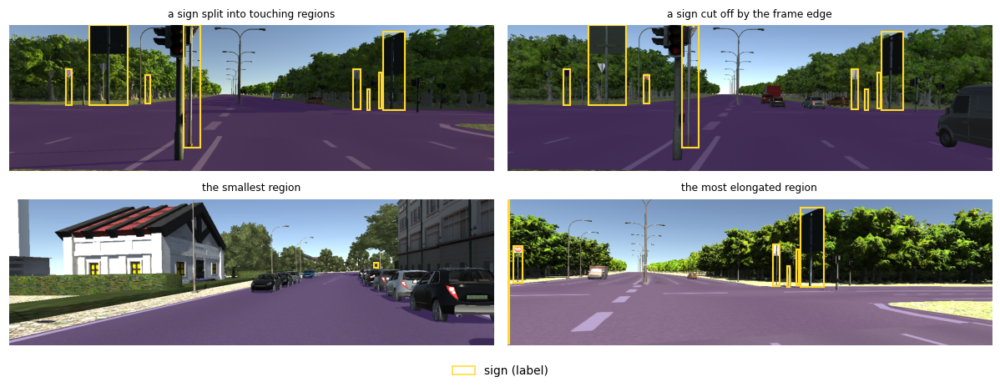

In [8]:
examples = sign_examples(described, RANDOM_SEED)
chosen = examples.merge(frames, on="frame_id")
fig = frame_panels(
    truth_panels(chosen, boxes_by_frame(signs), chosen["reason"].tolist()), columns=2
)
save_figure(fig, "sign_region_examples", "cleaning")
plt.show()

**The label includes the sign's post, and signs seen from behind:** in the two frames at the top, from world 0006, where the car waits at the same intersection for many frames, the boxes cover the panels with their posts, a thin post on its own, and large dark rectangles that are sign panels seen from the back. The tall box at the right is one board next to its post, two regions 3 pixels apart, and the boxes at the top edge are panels the frame cuts off. The smallest region, 51 pixels, is a distant sign near the horizon of world 0001 (the yellow squares on the house are lit windows, not labels), and the most elongated is a post a few pixels wide, cut off by the left edge of the frame and dozens of times taller than wide.

**Decisions:**

- **Every region stays a sign:** the test is scored against these labels, and removing posts or rear views would need a rule this data cannot check. What that costs is measured instead of guessed.
- **Fragments stay separate:** a detection that covers a whole sign overlaps each of its pieces by less than an IoU of 0.5, so it is scored as a false alarm and two misses. Section 10 reports recall on fragments separately.
- **Cut-off signs stay:** their box is the visible part, and a car's camera sees signs cut off by its frame too.
- **Signs under 51 pixels have no label:** their pixels are unlabeled, so a detection there counts as a false alarm. This sets a floor on precision for the smallest, most distant signs.
- **No frame is removed:** every frame decodes, and the near-copies among them (neighboring frames, renderings of one moment) are the dataset's design rather than defects. Section 6 measures how close they are, and section 5 keeps each one inside a single partition.

## 5. Partitions

The five worlds are five different drives, and section 6 shows that the ten renderings of a moment share their labels almost exactly and that neighboring frames of one video are near-copies. Any split inside a world would put near-copies of one scene into two partitions and let the test score reward memory, so the split is by world: three worlds train, one validates, one tests. Five worlds cannot be cut into exact 60/20/20 shares; the assignment below is the one closest to them by moments that keeps three worlds for training, with the larger of the two held-out worlds as the test set. The test world opens once, in section 10, and no choice before that reads its labels.

In [9]:
parts = split_frames(frames)
train, val, test = parts["train"], parts["validation"], parts["test"]
partitioned = frames.assign(partition=assign_partitions(frames, PARTITIONS))
group_summary(partitioned, "partition").loc[list(PARTITIONS)]

,worlds,moments,share of moments,frames,renderings,signs per frame,frames with a sign,road share
partition,,,,,,,,
train,"0002, 0006, 0020",1340,0.630,13400,10,3.235,0.881,0.257
validation,0018,339,0.159,3390,10,1.084,0.806,0.192
test,0001,447,0.210,4470,10,1.194,0.601,0.232


**The split is 63/16/21 by moments, and the held-out worlds have far fewer signs than training:** the three training worlds hold 1,340 moments (63.0%) and 13,400 frames with 3.2 signs per frame, many of them from world 0006. Validation (world 0018, 15.9%) and test (world 0001, 21.0%) have about one sign per frame, 1.08 and 1.19, and the test world has the fewest frames with any sign at all (60.1%). Detection on the held-out worlds is therefore judged on fewer, sparser signs than the network trains on.

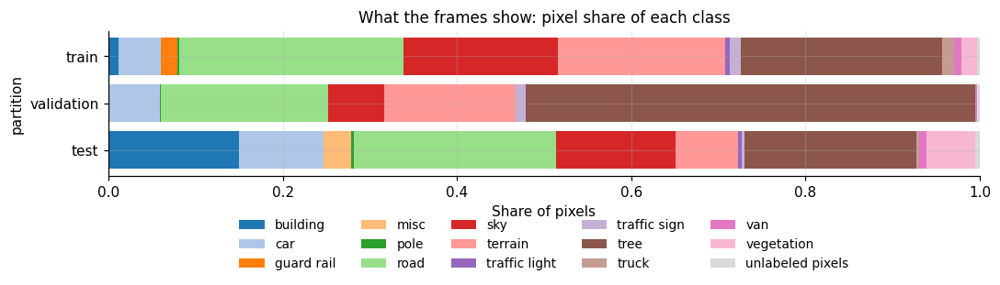

partition,train,validation,test
building,0.011,0.000,0.149
car,0.049,0.059,0.097
guard rail,0.019,0.000,0.000
misc,0.000,0.000,0.032
pole,0.002,0.001,0.003
road,0.257,0.192,0.232
sky,0.177,0.064,0.137
terrain,0.192,0.152,0.072
traffic light,0.006,0.000,0.004
traffic sign,0.012,0.011,0.003


In [10]:
partition_shares = class_shares(partitioned, by="partition").loc[list(PARTITIONS)]
fig = plot_class_shares(partition_shares)
save_figure(fig, "class_shares_by_partition", "partitions")
plt.show()
partition_shares.T

**The test world is the only urban one:** buildings take 14.9% of its pixels against 1.1% in training and none in validation, and it is the only world with a sizable `misc` class (3.2%), the street furniture and surfaces of a town. Validation is a road through woods, with trees on 51.6% of its pixels. None of this enters a decision (no choice before section 10 reads the test world), but it predicts where the network will struggle: on surfaces next to the road that the training worlds rarely show.

## 6. Exploratory data analysis

Every measurement that feeds a decision in this section uses the training worlds only. The questions are chosen for what the network needs: what the scenes look like, how small and how elongated the signs are (which decides the anchor boxes), how much the renderings and neighboring frames repeat each other (which decides the split and the sampling), and how fine a mask must be to describe the road (which decides the road head).

### The worlds and their renderings

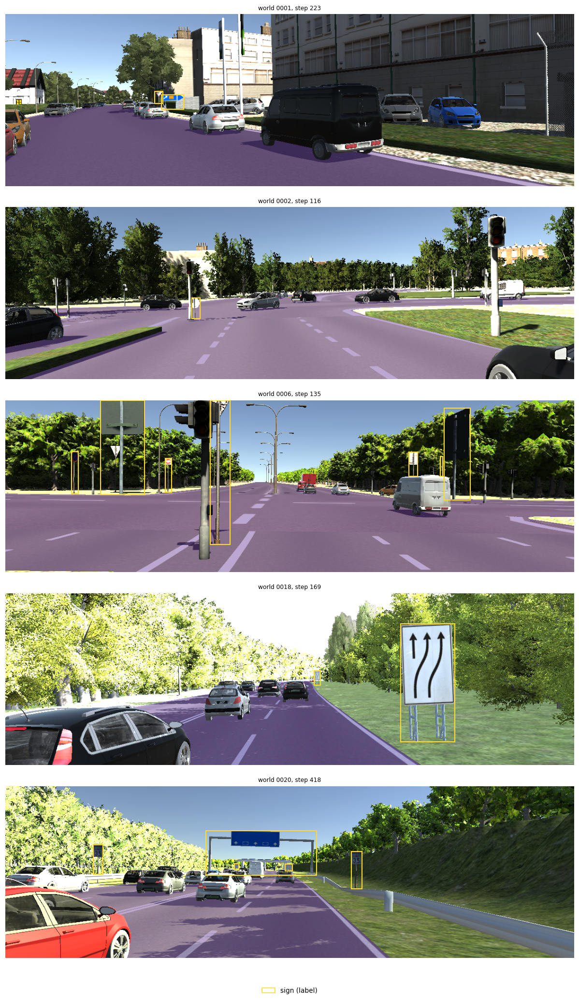

In [11]:
middle = world_examples(frames, REPETITION_VARIATION)
titles = [
    f"world {world}, step {step}"
    for world, step in zip(middle["world"], middle["step"], strict=True)
]
fig = frame_panels(truth_panels(middle, boxes_by_frame(signs), titles), columns=1)
save_figure(fig, "one_frame_per_world", "eda")
plt.show()

**Five different drives:** world 0001 is a town street lined with buildings and parked cars, 0002 an intersection among trees, 0006 a wide avenue with traffic lights and many signs, 0018 a road through dense trees with one large lane sign close to the camera, and 0020 a highway with guard rails and an overhead gantry, which the dataset labels as one sign region from post to post. The road label (purple) covers the carriageway only, and the grass, gravel and pavement beside it carry other classes.

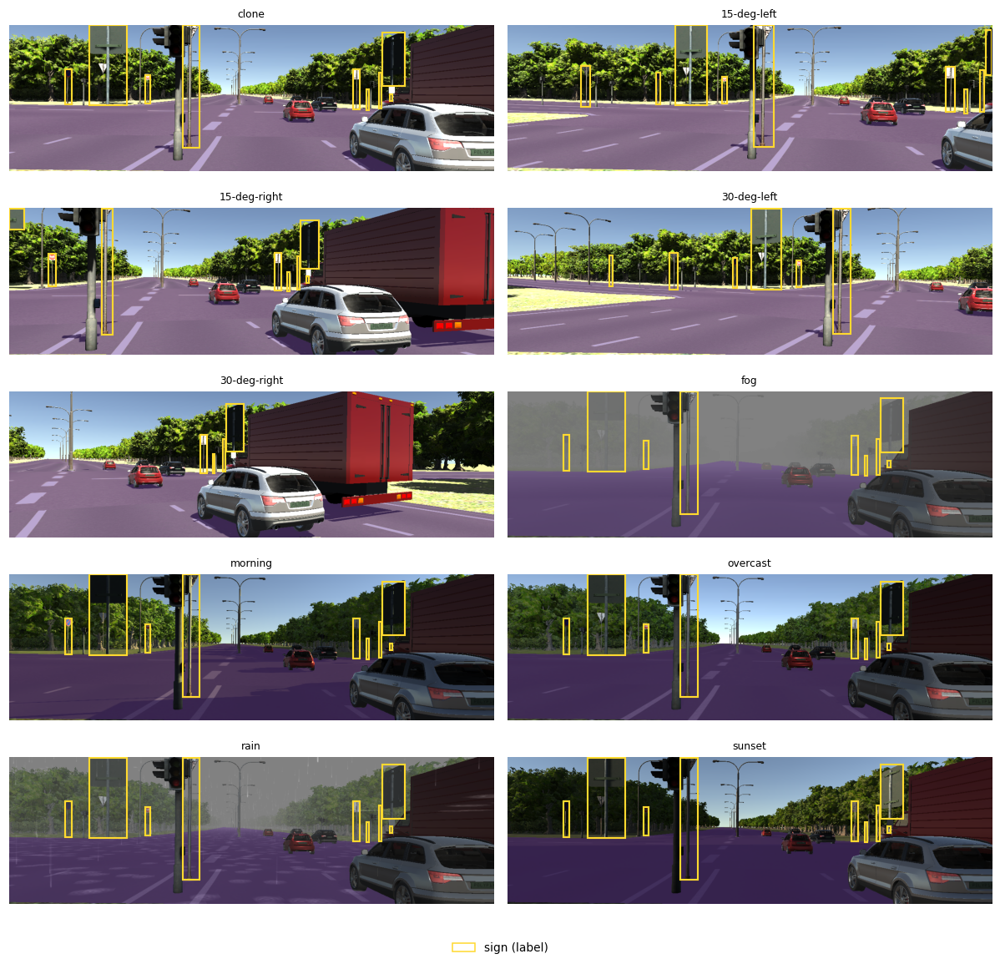

In [12]:
clone = train[train["variation"] == REPETITION_VARIATION]
busiest = clone.loc[clone["signs"].idxmax()]
moment = rendering_examples(frames, busiest["world"], busiest["step"])
fig = frame_panels(
    truth_panels(moment, boxes_by_frame(signs), moment["variation"].tolist()), columns=2
)
save_figure(fig, "ten_renderings", "eda")
plt.show()

**Two kinds of rendering:** the busiest training moment (world 0006, step 75, with 9 sign regions) shows what each rendering changes. The five weather and light renderings keep the clone's exact geometry and change only the picture: fog washes out the distance, rain adds streaks and wet reflections, and sunset and overcast darken everything. The four rotated cameras show the same moment from a camera turned 15 or 30 degrees, so the road and the signs sit elsewhere in the frame, and some signs leave it while others enter.

### What each world shows

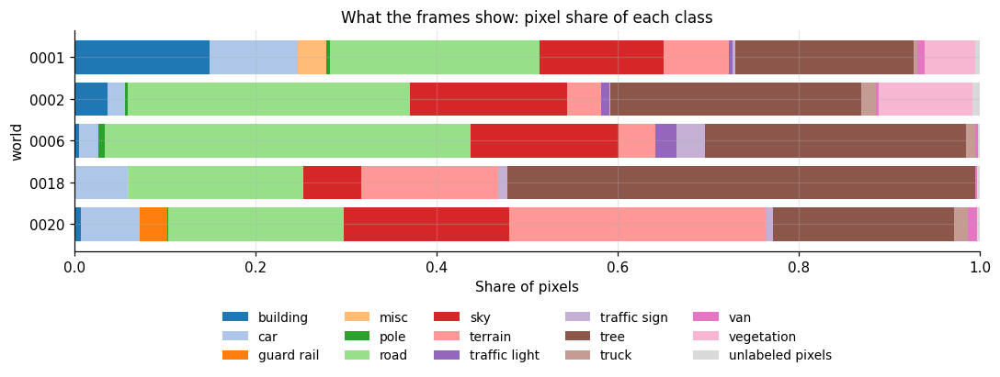

world,0001,0002,0006,0018,0020
building,0.149,0.036,0.005,0.000,0.006
car,0.097,0.020,0.021,0.059,0.066
guard rail,0.000,0.000,0.000,0.000,0.031
misc,0.032,0.000,0.000,0.000,0.000
pole,0.003,0.004,0.007,0.001,0.001
road,0.232,0.311,0.403,0.192,0.195
sky,0.137,0.174,0.164,0.064,0.182
terrain,0.072,0.038,0.041,0.152,0.284
traffic light,0.004,0.009,0.023,0.000,0.000
traffic sign,0.003,0.001,0.031,0.011,0.008


In [13]:
world_shares = class_shares(frames, by="world")
fig = plot_class_shares(world_shares)
save_figure(fig, "class_shares_by_world", "eda")
plt.show()
world_shares.T

**The worlds differ in what surrounds the road:** world 0001 has buildings (14.9%), cars (9.7%) and `misc` (3.2%); 0006 has the most road (40.3%) and the most signs and traffic lights (3.1% and 2.3% of its pixels); 0018 is mostly trees (51.6%); and 0020 has open terrain (28.4%) and guard rails (3.1%). `vegetation` appears only in 0001 and 0002. The training worlds cover avenues, intersections and a highway but almost no town, which the class shares by partition already showed.

### Sign shapes and sizes

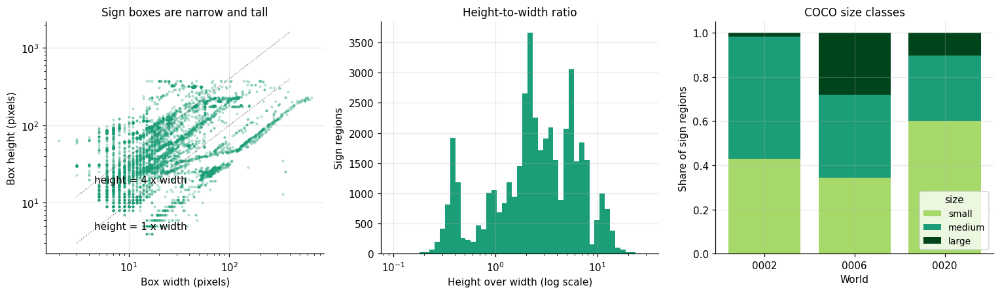

,training sign regions
regions,43353.000
median width (px),19.000
median height (px),58.000
median height over width,2.557
share more than 10 times taller than wide,0.057
median share of the box the region fills,0.445
share small (COCO),0.488
share medium (COCO),0.341
share large (COCO),0.171
share cut off by the frame edge,0.150


size,small,medium,large
world,,,
0002,0.429,0.553,0.018
0006,0.344,0.375,0.282
0020,0.600,0.296,0.104


In [14]:
train_signs = described[described["frame_id"].isin(set(train["frame_id"]))]
fig = plot_sign_shapes(train_signs)
save_figure(fig, "sign_shapes", "eda")
plt.show()
display(sign_summary(train_signs).to_frame("training sign regions"))
pd.crosstab(train_signs["world"], train_signs["size"], normalize="index")

**Training signs are small, tall and come in a few recurring shapes:** the 43,353 training regions have the same median box as the whole set, 19 x 58 pixels, with a median height-to-width ratio of 2.56, and 48.8% are small by COCO's definition. The ratio has several peaks rather than one: wide boxes around 0.4, almost all from the highway world 0020 and its overhead gantries, a main peak between 2 and 3 (a panel on its post), and taller peaks near 6 and 12, mostly world 0006's posts. The straight streaks in the scatter are single signs tracked over many frames, growing at a constant shape as the car approaches. World 0020 has the most small signs (60.0%), and 0006 the most large ones (28.2%), the world whose car spends long stretches close to the same signs. These shapes decide the anchor boxes below, and they warn that recall will be lowest on the small signs.

### Where signs and road appear in the frame

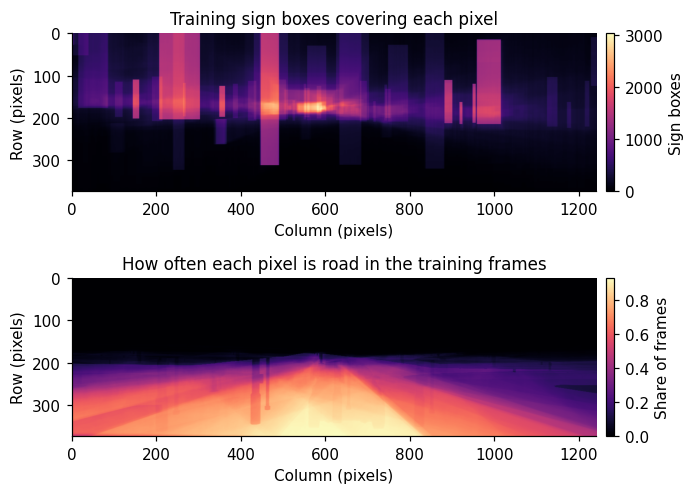

In [15]:
sign_map = box_heatmap(train_signs[BOX_COLUMNS].to_numpy(), FRAME_HEIGHT, FRAME_WIDTH)
road_map = class_frequency(one_rendering_per_step(train), ROAD_INDEX)
maps = {
    "Training sign boxes covering each pixel": (sign_map, "Sign boxes"),
    "How often each pixel is road in the training frames": (road_map, "Share of frames"),
}
fig = plot_heatmaps(maps)
save_figure(fig, "where_signs_and_road_appear", "eda")
plt.show()

**Signs line the horizon, and the road fills the lower middle:** sign boxes concentrate in a band along the horizon, most densely near the vanishing point, where distant signs are small, and the bright rectangles above it are the same signs held in place over many frames while world 0006's car waits. The road is almost never above the horizon and is most often in the lower middle of the frame, since the camera sits at the same height and angle in every video.

**A baseline for the road head:** the frequency map already predicts the road to some degree, since the camera is mounted the same way in every video. A fixed mask, the pixels that are road in at least half of the training frames, called road in every frame without looking at it, is the score the road head has to beat. It is scored here on the validation world.

In [16]:
prior = road_map >= ROAD_THRESHOLD
prior_scores = road_scores(fixed_mask_counts(prior, one_rendering_per_step(val)))
pd.Series(prior_scores).to_frame("fixed road mask, validation moments")

,"fixed road mask, validation moments"
road_iou,0.557
miou,0.697
pixel_accuracy,0.865
road_precision,0.601
road_recall,0.885


**Knowing where road usually is already gives a road IoU of 0.557:** the fixed mask finds 88.5% of the validation road (recall 0.885), but only 60.1% of what it calls road is road (precision 0.601), and its pixel accuracy is 0.865, which shows how little pixel accuracy says on its own. A road head that does not clearly beat 0.557 has learned the camera's geometry and little else.

### Light and weather across the renderings

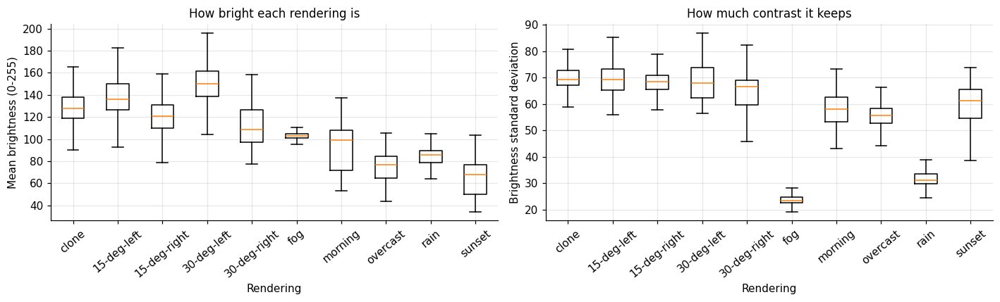

,brightness,contrast
variation,,
clone,127.494,69.415
15-deg-left,136.122,69.383
15-deg-right,120.655,68.375
30-deg-left,149.998,68.000
30-deg-right,108.569,66.750
fog,102.962,23.413
morning,99.136,58.140
overcast,76.520,55.756
rain,85.971,31.148


In [17]:
fig = plot_rendering_light(train)
save_figure(fig, "rendering_light", "eda")
plt.show()
train.groupby("variation")[["brightness", "contrast"]].median().loc[list(VARIATIONS)]

**Fog and rain take most of the contrast away:** the median brightness standard deviation is 23.4 in fog and 31.1 in rain against 69.4 for the clone, so the small, distant signs fade into the background, and sunset is the darkest rendering (median brightness 67.9 against 127.5). The rotated cameras keep the clone's contrast (66.8 to 69.4) and change only the brightness, from 108.6 to 150.0, as they turn toward brighter or darker parts of the scene. Every rendering is shown in training, and section 10 scores each one separately to see which conditions cost the most.

### Do the renderings of a moment share their labels?

For 40 random moments of each training world, the road mask and the sign boxes of every rendering are compared with the clone's: the IoU of the two road masks, and the share of the clone's sign boxes that a box of the other rendering overlaps by an IoU of at least 0.5.

In [18]:
agreement = rendering_agreement(
    train, signs, REPETITION_VARIATION, SAME_SIGN_IOU, RENDERING_STEPS, RANDOM_SEED
)
agreement

,road_iou,signs_matched
variation,,
15-deg-left,0.650,0.001
15-deg-right,0.646,0.001
30-deg-left,0.536,0.000
30-deg-right,0.499,0.000
fog,1.000,1.000
morning,1.000,1.000
overcast,1.000,1.000
rain,1.000,1.000
sunset,1.000,1.000


**The weather renderings are the same labels under another sky, the rotated cameras are not:** for all five weather and light renderings the road IoU with the clone is 1.000 and every clone sign box is matched, so they are exact label copies of the clone. The rotated cameras see the same moment from elsewhere: their road masks overlap the clone's by 0.499 to 0.650, and practically none of the clone's sign boxes reappear at the same place. A split that put two renderings of one moment into two partitions would test the network on labels it trained on, which rules out any split inside a world.

### How fast the scene changes along a video

The same two comparisons between frames of one video a given number of steps apart, in the clone rendering of each training world. They say how many frames it takes before a frame stops repeating its neighbors.

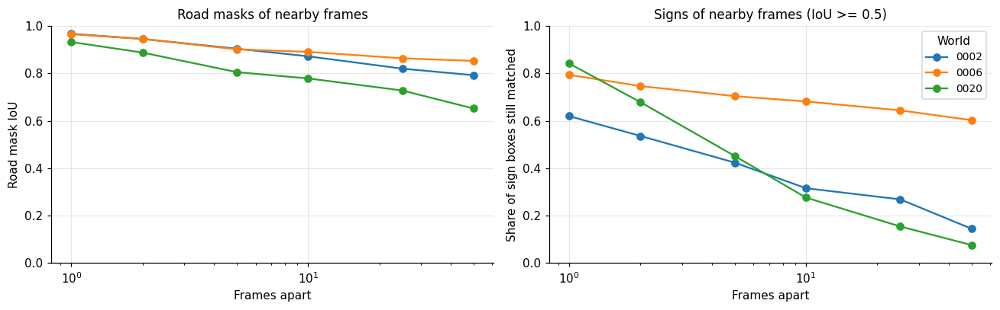

road_iou             signs_still_matched            
world     0002  0006  0020                0002  0006  0020
lag                                                       
1        0.967 0.966 0.933               0.620 0.794 0.842
2        0.946 0.946 0.888               0.536 0.747 0.679
5        0.904 0.902 0.806               0.424 0.704 0.452
10       0.872 0.891 0.779               0.316 0.682 0.277
25       0.820 0.864 0.728               0.269 0.644 0.155
50       0.793 0.853 0.652               0.145 0.603 0.076

In [19]:
repetition = frame_repetition(train, signs, REPETITION_LAGS, REPETITION_VARIATION, SAME_SIGN_IOU)
fig = plot_repetition(repetition)
save_figure(fig, "repetition", "eda")
plt.show()
repetition.pivot(index="lag", columns="world", values=["road_iou", "signs_still_matched"])

**Neighboring frames are near-copies, and signs stay in view for dozens of frames:** one step apart, the road masks overlap by 0.967, 0.966 and 0.933 in the three training worlds, and 62% to 84% of the sign boxes are still in the same place. Fifty steps apart, world 0006 still matches 60.3% of its signs, because its car waits at intersections, while world 0020's highway has moved on (7.6%).

**Decisions:** a split by frames, even with renderings kept together, would put near-copies on both sides, so the split is by world (section 5). And a pass over all 13,400 training frames would mostly repeat itself: each epoch instead shows every training moment once, under the next of its ten renderings, so eight epochs show each moment under eight renderings for the cost of 1,340 frames per epoch.

### Anchor boxes for small, tall signs

The RPN can only propose a sign that some anchor overlaps well: in training, an anchor counts as a positive from an IoU of 0.7 with a sign (or as the best anchor a sign has), and as background below 0.3. For every training sign box, the table gives the best IoU any anchor of each candidate set reaches with it, computed exactly from the anchor grid of each pyramid level. The COCO defaults are sizes 32 to 512 with height-to-width ratios 0.5, 1 and 2.

,median best IoU,best IoU >= 0.3,best IoU >= 0.5,best IoU >= 0.7
COCO defaults,0.439,0.720,0.412,0.160
one octave smaller,0.524,0.904,0.550,0.144
"one octave smaller, taller ratios",0.611,0.974,0.866,0.254
"half-octave steps, taller ratios",0.709,0.974,0.885,0.546


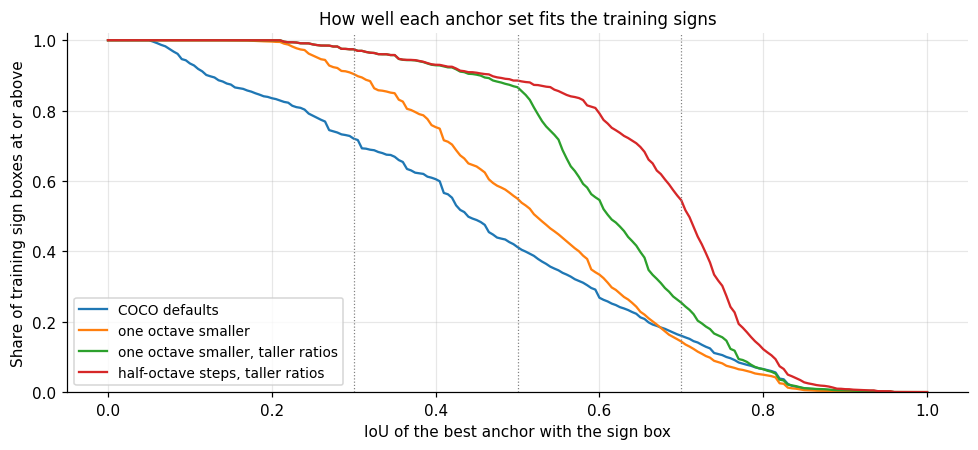

In [20]:
boxes = train_signs[BOX_COLUMNS].to_numpy()
display(anchor_coverage(boxes, ANCHOR_CANDIDATES, ANCHOR_IOU_LEVELS))
best = {name: best_anchor_iou(boxes, *anchors) for name, anchors in ANCHOR_CANDIDATES.items()}
fig = plot_anchor_coverage(best, ANCHOR_IOU_LEVELS)
save_figure(fig, "anchor_coverage", "eda")
plt.show()

**COCO's anchors miss most of these signs, and smaller, taller anchors fix it:** with the COCO defaults, only 41.2% of the training sign boxes have an anchor that overlaps them by an IoU of 0.5, and 16.0% one at 0.7, the RPN's threshold for a positive. Starting one octave smaller helps the small signs (55.0% at 0.5), adding taller ratios helps far more (86.6%), and half-octave sizes with ratios from 0.5 to 8 do best: 88.5% at 0.5, 54.6% at 0.7 and a median best IoU of 0.709 against 0.439. **Decision:** the network uses that last set, ten anchors per position (sizes 16 and 23 on the finest level, doubling per level, times five ratios). The RPN also takes each sign's best anchor as a positive whatever its IoU, so COCO anchors would not make signs invisible, only harder to propose well; section 9 trains with them to measure the difference.

### What kind of head can draw the road?

A Mask R-CNN mask head draws a 28 x 28 mask inside an object's box and stretches it over the box, while a semantic head predicts on a grid four times coarser than the frame and upsamples. Each true road mask of 600 random training frames is squeezed through both bottlenecks and compared with itself, which gives the best road IoU each kind of head could reach if it predicted perfectly.

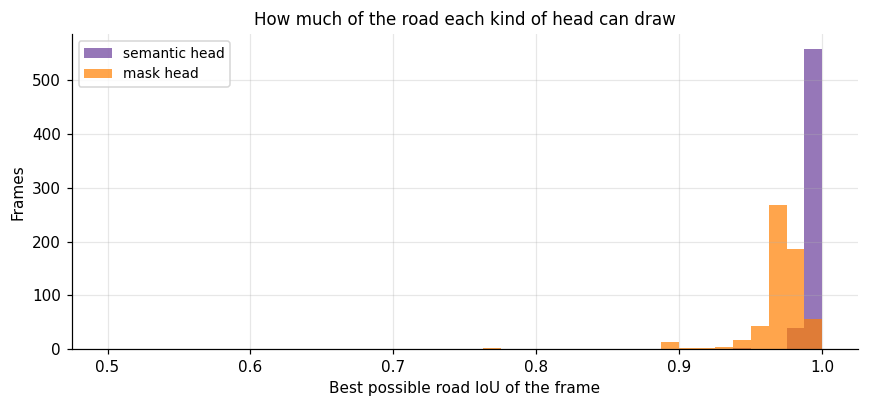

,semantic head,mask head
count,600.000,600.000
mean,0.995,0.969
std,0.005,0.023
min,0.945,0.759
25%,0.995,0.967
50%,0.996,0.973
75%,0.997,0.979
max,0.999,0.995


In [21]:
ceilings = coarse_mask_ceilings(train.sample(CEILING_FRAMES, random_state=RANDOM_SEED))
fig = plot_mask_ceiling(ceilings)
save_figure(fig, "mask_ceiling", "eda")
plt.show()
ceilings[["semantic head", "mask head"]].describe()

**Both kinds of head could draw this road, but the semantic head has the higher and steadier ceiling:** squeezed through the semantic head's stride-4 grid, the true road masks keep a median IoU of 0.996 and never drop below 0.945; through a 28 x 28 mask stretched over the road's box they keep a median of 0.973 and fall to 0.759 on the worst frame. Resolution alone would not rule out a mask head, so the deciding reason is structural: a mask head draws inside a detected box, so it would first have to detect "the road" as one object, a region with no instances that runs into the frame's edges. **Decision:** the road gets the semantic head of Panoptic FPN, a per-pixel classifier on the same feature pyramid as the detector.

### What the exploration decided

| Finding | Decision |
|---|---|
| Weather renderings copy the clone's labels exactly; neighboring frames overlap by a road IoU of 0.93 to 0.97 | split by world; each epoch shows every moment once, under the next rendering |
| Signs are small (48.8% under 32 x 32 pixels) and tall (median height-to-width 2.56) | frames at their native 1242 x 375; anchors from 16 pixels in half-octave steps with ratios up to 8 |
| COCO anchors reach an IoU of 0.5 for 41.2% of the training signs, the adapted set for 88.5% | adapted anchors; COCO anchors trained as a variant in section 9 |
| A semantic head's ceiling is 0.996 (median road IoU), a mask head's 0.973, with a worst frame of 0.759 | the semantic branch of Panoptic FPN for the road |
| A fixed road mask scores a road IoU of 0.557 on validation | the baseline the road head must beat |
| Fog and rain cut the contrast to a third and a half of the clone's | every rendering in training; scores per rendering in section 10 |
| The test world is the only urban one | no decision; section 10 checks whether the gap it predicts appears |

## 7. The multi-task network

The network is torchvision's Faster R-CNN with a ResNet-50 FPN backbone and COCO weights, plus a road head on the same feature pyramid. One forward pass runs the backbone once and both heads on its output.

**The backbone:** ResNet-50 (He et al. 2016) is a stem (a 7 x 7 convolution and max pooling, stride 4) followed by four stages of bottleneck blocks, `layer1` to `layer4`, at strides 4, 8, 16 and 32. A bottleneck block applies a 1 x 1, a 3 x 3 and a 1 x 1 convolution and adds its input back to the result, so each block learns a correction to what it receives and the gradient also flows back through the unchanged identity path, which is what lets fifty layers train. The batch-norm layers are frozen: COCO detectors are trained with batches too small to estimate batch statistics, so torchvision's weights fix each batch norm's mean, variance and scale, and it acts as a constant affine transform (with the zero epsilon of those weights).

**The feature pyramid** (Lin et al. 2017): deep stages see a wide context at a coarse resolution, early stages a narrow context at a fine one. The FPN projects each stage's output to 256 channels with a 1 x 1 convolution, adds to it the upsampled map from the stage above, and smooths each sum with a 3 x 3 convolution. The result is four maps at strides 4, 8, 16 and 32 that all carry the deep stages' semantics, plus a fifth at stride 64 pooled from the last, so small signs are found on the fine maps and large ones on the coarse maps.

**The proposal network (RPN):** a 3 x 3 convolution over every pyramid level, followed by two 1 x 1 convolutions that give, for each anchor at each position, an objectness logit and four offsets (shifts of the center in units of the anchor's size and log-scale changes of its width and height). With the adapted anchors chosen in section 6 there are ten anchors per position, two sizes times five height-to-width ratios. In training, 256 anchors per frame are sampled, at most half of them positives (IoU of at least 0.7 with a sign, or the best anchor a sign has), and the loss is binary cross-entropy on objectness plus a smooth L1 loss on the offsets of the positives. At inference the highest-scoring proposals of every level go through non-maximum suppression, and 1,000 per frame continue.

**RoIAlign and the box head:** each proposal is assigned to the pyramid level that suits its size and its features are sampled onto a 7 x 7 grid by bilinear interpolation at exact, unrounded positions (RoIAlign, He et al. 2017), which matters for boxes only a few feature cells wide. Two fully connected layers of 1,024 units feed a two-way classifier (sign or background, cross-entropy) and a box regressor (smooth L1). Training samples 512 proposals per frame, at most a quarter of them positives (IoU of at least 0.5 with a sign). At inference, detections with a confidence of at least 0.05 go through non-maximum suppression at an IoU of 0.5, and at most 100 are kept per frame.

**The road head:** the semantic branch of Panoptic FPN (Kirillov et al. 2019) with a single output channel. Each of the four pyramid levels goes through as many steps of a 3 x 3 convolution, group normalization, ReLU and 2x bilinear upsampling as it needs to reach stride 4, the four results are summed, and a 1 x 1 convolution gives one road logit per position, which bilinear upsampling brings to the frame's 1242 x 375 pixels. The loss is binary cross-entropy per pixel, averaged over the labeled pixels. A sigmoid turns the logit into a probability, and a pixel is called road from 0.5.

**Transfer from COCO:** the ResNet, the FPN, the RPN's 3 x 3 convolution and the box head's two hidden layers start from the COCO detector, whose 80 classes include stop signs and traffic lights but nothing like a road. The sign classifier and box regressor, the RPN's two output layers (the anchor count changed from three to ten) and the whole road head start from random weights. The frames go in at their own resolution: the detector's built-in resize is set to 1242 x 375, so no sign loses pixels to interpolation.

In [22]:
parameters = parameter_counts(build_model(), {"stage one": 0, "stage two": FINETUNE_STAGES})
display(parameters)
(parameters.loc["total"] / parameters.loc["total", "parameters"]).to_frame("share of all weights")

,parameters,trained in stage one,trained in stage two
ResNet stem,9408,0,0
ResNet layer1,212992,0,0
ResNet layer2,1212416,0,1212416
ResNet layer3,7077888,0,7077888
ResNet layer4,14942208,0,14942208
feature pyramid,3344384,0,3344384
proposal network,602930,602930,602930
box head,13905930,13905930,13905930
road head,1624833,1624833,1624833
total,42932989,16133693,42710589


,share of all weights
parameters,1.000
trained in stage one,0.376
trained in stage two,0.995


**Stage one trains 37.6% of the weights, stage two 99.5%:** the network has 42.9 million weights. In stage one only the three heads learn: the box head (13.9 million, almost all in its first fully connected layer, which reads 256 x 7 x 7 = 12,544 values per proposal), the road head (1.6 million) and the RPN (0.6 million). Stage two adds the feature pyramid and ResNet stages 2 to 4 and leaves only the stem and `layer1` frozen, 0.2 million weights that compute edges and textures any task can use.

### The optimizer and the schedule

**Stochastic gradient descent with momentum**, the optimizer of the Faster R-CNN, Mask R-CNN and Panoptic FPN papers, with momentum 0.9 and weight decay 0.0001. At every step, for each trained weight w with gradient g on the batch, PyTorch computes:

1. g ← g + 0.0001 · w, the weight decay, which pulls every weight slightly toward zero and keeps the new heads from fitting the training worlds with large weights;
2. v ← 0.9 · v + g, the velocity, a running sum of past gradients in which each step's contribution fades by a factor of 0.9 per step, so directions the batches agree on build up to about ten times a single gradient while directions they disagree on cancel;
3. w ← w − η · v, the step itself, with the learning rate η.

**Warmup and cosine:** η climbs linearly from 0.1% of its peak to the peak over the first 100 steps, because the new heads start random and their first gradients are large and erratic, then follows half a cosine down to zero at the end of the stage, so the steps are large while the weights are far from a good solution and small when they are close.

**Two stages, the transfer-learning recipe:** stage one trains only the heads for 2 epochs at a peak rate of 0.01, with the backbone and the FPN frozen; a randomly initialized head sends noise back into whatever it reads, so the pretrained features are protected until the heads have learned something. Stage two continues from stage one's kept weights for 6 epochs at 0.005 and also fine-tunes the FPN and the last three ResNet stages. The rate 0.005 is torchvision's reference rate of 0.02 for batches of 16, scaled linearly to this project's batches of 4 (Goyal et al. 2017). The stem and `layer1` stay frozen in both stages: they compute generic edges and textures, and freezing them saves memory and time.

**Equal training of the two tasks:** in stage one nothing shared is trained, so the tasks cannot interfere. In stage two the trainer balances their pulls on the shared features as section 2 describes, measuring each pull every 10 steps and smoothing it with a momentum of 0.9.

## 8. Training

**What one epoch shows:** each training epoch shows every moment of the three training videos once (1,340 frames), each under the next of its ten renderings, and mirrors a frame left to right at a rate of 0.5, the one augmentation of the Faster R-CNN and Mask R-CNN papers. Section 6 showed that the renderings of a moment share their labels and that neighboring frames repeat each other, so a pass over all 13,400 training frames would cost ten times as much for little new information. The eight epochs of the recipe together show each moment under eight renderings. Validation uses one rendering per moment of world 0018 (339 frames), the same frames every epoch.

**The epoch kept:** both heads come from one network, so the epoch kept is the one with the best validation score, the mean of the validation AP50 and the validation road IoU, and every number reported for a run comes from the weights of that epoch, loaded back from its checkpoint.

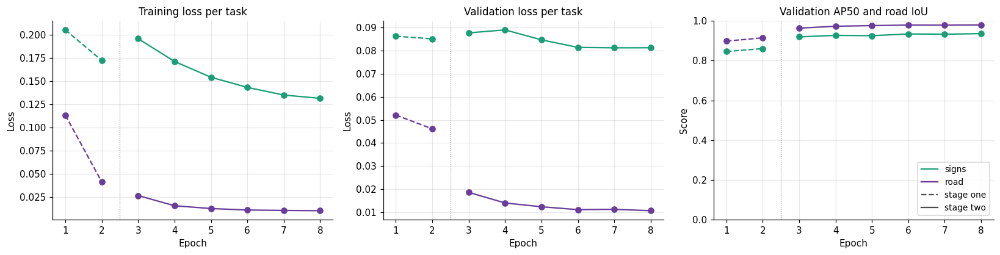

In [23]:
heads, tuned = train_recipe(train, val, signs)
histories = {"stage one": read_history(heads), "stage two": read_history(tuned)}
fig = plot_history(histories)
save_figure(fig, "history", "training")
plt.show()

In [24]:
history = pd.concat(histories, names=["stage", "row"]).reset_index(level="row", drop=True)
columns = ["epoch", "train_loss", "val_loss_road", "val_sign_ap50", "val_sign_map", "val_road_iou"]
history[[*columns, "val_score"]]

,epoch,train_loss,val_loss_road,val_sign_ap50,val_sign_map,val_road_iou,val_score
stage,,,,,,,
stage one,1,0.318,0.052,0.846,0.520,0.898,0.872
stage one,2,0.213,0.046,0.860,0.559,0.914,0.887
stage two,1,0.222,0.019,0.919,0.623,0.963,0.941
stage two,2,0.187,0.014,0.927,0.642,0.973,0.950
stage two,3,0.167,0.012,0.925,0.679,0.976,0.951
stage two,4,0.154,0.011,0.934,0.709,0.979,0.956
stage two,5,0.145,0.011,0.933,0.708,0.978,0.956
stage two,6,0.142,0.011,0.936,0.705,0.980,0.958


**The COCO features already carry most of both tasks, and fine-tuning adds the rest without overfitting:** with the backbone frozen, two epochs of training the heads reach a validation AP50 of 0.860 and a road IoU of 0.914, so features learned on everyday photographs already separate signs and road well. Fine-tuning lifts both in its first epoch (0.919 and 0.963) and keeps improving them more slowly: the validation road loss falls from 0.019 to 0.011, the detection's validation loss in the middle panel stays flat after its third epoch, and the scores level off over the last three epochs (AP50 0.934 to 0.936, road IoU 0.979 to 0.980) as the cosine schedule brings the learning rate to zero. Nothing turns back up, so eight epochs do not overfit these three worlds. The stricter COCO mAP climbs from 0.623 to 0.709 at epoch 4, which says the boxes get tighter with fine-tuning, not only more numerous. The epoch kept is the sixth, with a validation score of 0.958 (AP50 0.936, road IoU 0.980). Part of the gain over stage one is simply six more epochs; the `frozen` run in section 9 trains the heads for the same eight epochs without touching the backbone, which separates the two.

### Did the two tasks train equally?

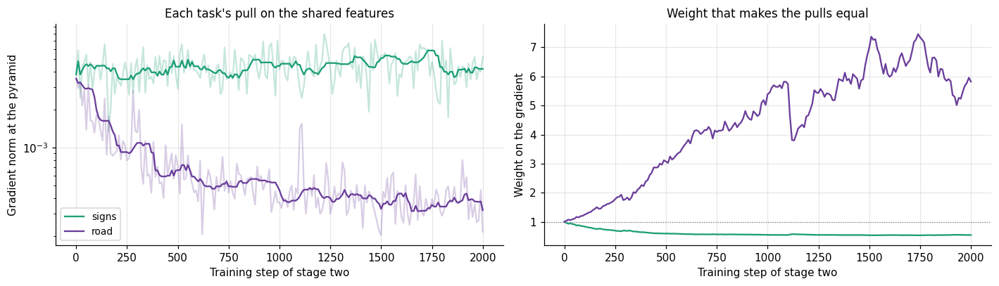

,signs_over_road,weight_signs,weight_road
epoch,,,
1,2.923,0.762,1.455
2,7.132,0.597,3.072
3,8.371,0.565,4.328
4,9.550,0.551,5.407
5,11.808,0.545,6.113
6,12.131,0.544,6.242


In [25]:
pulls = read_pulls(tuned)
fig = plot_pulls(pulls)
save_figure(fig, "pulls", "training")
plt.show()
ratio = pulls["pull_signs"] / pulls["pull_road"]
balance = pulls.assign(epoch=pulls["epoch"] + 1, signs_over_road=ratio)
balance.groupby("epoch")[["signs_over_road", "weight_signs", "weight_road"]].median()

**Left alone, the signs would steer the shared backbone:** the gradient the detection losses send into the pyramid is 2.9 times the road's in the first epoch of fine-tuning and 12.1 times in the last, because the road loss shrinks faster than the detection losses. Adding the two losses as they are would let the signs set about nine tenths of the direction the shared weights move. The balancing gives the road's gradient a weight that climbs from 1.5 to 6.2 and the signs' a weight that settles near 0.54, so both arrive at the backbone with the same norm while their sum stays what it was. Whether this changes either score is an empirical question, and the `sum` run of section 9 answers it.

## 9. How much is left in the recipe

The recipe above comes from one seed and one value of every setting. Three kinds of runs test it, all trained to full length:

- **The seed:** the full two-stage recipe again with seeds 43 and 44, which change the random heads, the order of the frames, the flips and the proposals sampled for the box head. The spread of the three runs is the noise any other difference has to beat.
- **Candidates that could replace the recipe,** each changing one setting of stage two and starting from the same seed-42 heads: the plain sum of the losses instead of the balanced gradients (`sum`), and the learning rate halved and doubled (`lr_0.0025`, `lr_0.01`), which brackets the recipe's 0.005. The doubled rate won at the top of that bracket, so a further doubling (`lr_0.02`) was added afterwards to bracket the winner. A last candidate replaces the adapted anchors with the COCO defaults; it needs its own stage one, because the RPN's output layers change shape with the anchor count.
- **Baselines that cannot replace it:** the same stage two training a single task (`signs_only`, `road_only`), which answers whether sharing the backbone costs either task anything, and the heads trained for six more epochs on the frozen backbone (`frozen`), which answers what fine-tuning the backbone adds.

**The rule, fixed before the runs:** a candidate replaces the recipe only if its validation score beats the mean of the recipe's three seeds by more than their range, and the best such candidate is carried forward. The single-task runs have no combined score, so they are compared task by task. Every comparison changes one setting of the starting recipe, so each measures its setting at a learning rate of 0.005.

In [26]:
recipes = {seed: train_recipe(train, val, signs, seed=seed) for seed in SEEDS}
runs = {tuned.name: tuned for _, tuned in recipes.values()}
for name in CANDIDATE_VARIANTS + BASELINE_VARIANTS:
    runs[name] = train_variant(name, train, val, signs, heads)
coco = train_recipe(train, val, signs, anchors="coco", prefix=COCO_ANCHOR_PREFIX)[1]
runs[coco.name] = coco
validation = pd.concat({name: best_epoch(run) for name, run in runs.items()}, axis=1).T
validation = validation.astype({"epoch": int})
validation

,epoch,minutes,val_sign_ap50,val_sign_map,val_road_iou,val_road_miou,val_pixel_accuracy,val_score
recipe_seed42,6,9.500,0.936,0.705,0.980,0.987,0.996,0.958
recipe_seed43,4,9.100,0.940,0.709,0.979,0.987,0.996,0.959
recipe_seed44,5,9.100,0.942,0.712,0.979,0.987,0.996,0.960
sum,6,9.000,0.942,0.722,0.973,0.983,0.995,0.958
lr_0.0025,6,9.100,0.932,0.685,0.975,0.984,0.995,0.954
lr_0.01,4,9.100,0.953,0.733,0.981,0.988,0.996,0.967
lr_0.02,1,7.700,0.925,0.613,0.969,0.981,0.994,0.947
signs_only,6,7.800,0.947,0.726,NaN,NaN,NaN,0.947
road_only,4,5.400,NaN,NaN,0.975,0.985,0.995,0.975
frozen,5,6.100,0.869,0.612,0.926,0.954,0.985,0.898


**On validation, only the learning rate moves the score clearly beyond the seed noise:** the recipe's three seeds land within 0.003 of each other (validation score 0.958 to 0.960, AP50 0.936 to 0.942, road IoU 0.979 to 0.980). Halving the learning rate costs both tasks (score 0.954), doubling it to 0.01 helps both (AP50 0.953, mAP 0.733, road IoU 0.981, score 0.967), and doubling it again to 0.02 overshoots: its best epoch is the first (0.947), after which the larger steps make it worse, so 0.01 sits inside the bracket.

**Balancing the gradients trades the two tasks against each other:** the plain sum of the losses ties the recipe's score (0.958) with better signs (AP50 0.942, mAP 0.722) and a worse road (0.973), which is what the pulls predicted, since without the balancing the signs steer the backbone. **COCO's anchors are not the handicap section 6 suggested:** they give a higher AP50 than the adapted ones (0.944 against 0.936) but a lower mAP (0.691 against 0.705). The RPN takes each sign's best anchor as a positive whatever its overlap, and the box regression makes up for most of the mismatch, so the adapted anchors mainly buy tighter boxes.

**The baselines:** trained alone, the signs reach a slightly higher AP50 (0.947) and the road a slightly lower IoU (0.975) than in the shared network with the same settings (0.936 and 0.980), so on validation sharing the backbone costs the signs about a point of AP50 and gives the road half a point of IoU. The frozen backbone, whose heads train for the same eight epochs, stays far behind (AP50 0.869, road IoU 0.926): fine-tuning the backbone is worth 6.7 points of AP50 and 5.4 of road IoU on validation.

In [27]:
seed_runs = [f"recipe_seed{seed}" for seed in SEEDS]
verdicts = variant_verdicts(validation["val_score"], seed_runs, [*CANDIDATE_VARIANTS, coco.name])
final_name = carried_forward(verdicts, seed_runs[0])
print(f"carried forward: {final_name}")
verdicts

carried forward: lr_0.01


,val_score,points above the seed mean,seed range in points,replaces the recipe
sum,0.958,-0.147,0.271,False
lr_0.0025,0.954,-0.545,0.271,False
lr_0.01,0.967,0.818,0.271,True
lr_0.02,0.947,-1.192,0.271,False
coco_anchors_recipe_seed42,0.962,0.299,0.271,True


**Two candidates pass the rule, and the doubled learning rate is carried forward:** the rule asks for more than the recipe's seed range, 0.271 points of validation score above the mean of its seeds. The learning rate of 0.01 clears it by a wide margin (0.818 points), COCO's anchors only just (0.299), and the sum of the losses and the other two learning rates fall below the recipe's mean. The best passing candidate, `lr_0.01`, becomes the network carried forward. COCO's anchors pass by a hair's breadth with a lower mAP, so they are reported rather than combined with the new learning rate, a combination this one-change-at-a-time design does not test.

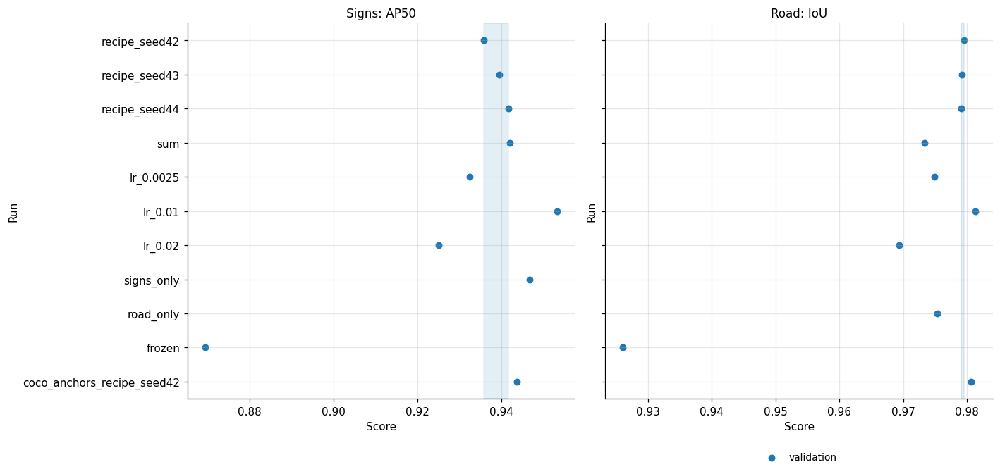

In [28]:
val_scores = validation.rename(columns=lambda name: name.removeprefix("val_"))
table, band = compare_runs({"validation": val_scores}, seed_runs)
fig = plot_runs(table, band)
save_figure(fig, "validation_runs", "comparison")
plt.show()

**Every run except the frozen backbone sits within a few points of the others on validation:** the shaded bands are the recipe's seed range, and most runs fall inside or close to them for both tasks. The validation world is too easy to separate the runs much, which section 10 comes back to.

### The network carried forward, with three seeds

The rule's reference was the recipe's seed spread, so the network carried forward is trained with the other two seeds as well, each from its own seed's stage one, to give it a spread of its own.

In [29]:
final_runs = train_seeds(final_name, train, val, signs, recipes)
runs |= final_runs
final_run = runs[final_name]
validation = pd.concat({name: best_epoch(run) for name, run in runs.items()}, axis=1).T
validation = validation.astype({"epoch": int})
validation.loc[list(final_runs) + seed_runs]

,epoch,minutes,val_sign_ap50,val_sign_map,val_road_iou,val_road_miou,val_pixel_accuracy,val_score
lr_0.01,4,9.100,0.953,0.733,0.981,0.988,0.996,0.967
lr_0.01_seed43,6,9.100,0.943,0.720,0.981,0.988,0.996,0.962
lr_0.01_seed44,6,9.100,0.955,0.724,0.982,0.989,0.997,0.968
recipe_seed42,6,9.500,0.936,0.705,0.980,0.987,0.996,0.958
recipe_seed43,4,9.100,0.940,0.709,0.979,0.987,0.996,0.959
recipe_seed44,5,9.100,0.942,0.712,0.979,0.987,0.996,0.960


**The gain of the higher learning rate holds over three seeds:** with seeds 42, 43 and 44 its validation scores are 0.967, 0.962 and 0.968, every one above the best recipe seed (0.960), with AP50 from 0.943 to 0.955 and road IoU from 0.981 to 0.982. The seed moves this network's score by 0.006, about twice the recipe's range, which is the noise to keep in mind when reading single numbers below.

## 10. Final evaluation on the test world

The test world opens here. Every run of section 9 is scored on the same 447 test frames, one rendering per moment of world 0001 as on validation, so validation and test compare like for like and the comparison costs a tenth of the full set. The network carried forward is then scored on all 4,470 test frames, by rendering and by sign size, and the drop from validation to test gets its own investigation.

### Every run on the test world

In [30]:
test_moments = one_rendering_per_step(test)
paths = {name: PREDICTION_DIR / f"{run.name}_test_moments.npz" for name, run in runs.items()}
predicted = {
    name: cached_predictions(run, test_moments, signs, paths[name]) for name, run in runs.items()
}
test_scores = pd.DataFrame({name: score_predictions(p, signs) for name, p in predicted.items()}).T
test_scores

,sign_ap50,sign_map,sign_ap75,sign_ap_small,sign_ap_medium,sign_ap_large,sign_ar100,road_iou,miou,pixel_accuracy,road_precision,road_recall
recipe_seed42,0.649,0.419,0.497,0.279,0.500,0.571,0.619,0.817,0.874,0.948,0.822,0.992
recipe_seed43,0.639,0.404,0.464,0.267,0.479,0.549,0.620,0.829,0.883,0.952,0.833,0.993
recipe_seed44,0.652,0.421,0.497,0.288,0.510,0.567,0.631,0.818,0.876,0.948,0.823,0.994
sum,0.673,0.453,0.537,0.299,0.534,0.633,0.650,0.820,0.877,0.949,0.826,0.991
lr_0.0025,0.593,0.371,0.434,0.240,0.448,0.529,0.605,0.825,0.881,0.951,0.831,0.991
lr_0.01,0.671,0.430,0.496,0.294,0.520,0.461,0.626,0.827,0.882,0.951,0.832,0.994
lr_0.02,0.676,0.411,0.450,0.267,0.506,0.455,0.625,0.858,0.904,0.962,0.865,0.991
signs_only,0.692,0.473,0.535,0.300,0.556,0.676,0.656,NaN,NaN,NaN,NaN,NaN
road_only,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.842,0.893,0.956,0.848,0.991
frozen,0.325,0.147,0.108,0.124,0.189,0.134,0.441,0.856,0.903,0.961,0.871,0.980


**Every network loses about a third of its sign AP50 and a sixth of its road IoU on the test world:** the recipe's seeds score AP50 0.639 to 0.652 on the 447 test moments against 0.936 to 0.942 on validation, and road IoU 0.817 to 0.829 against 0.979 to 0.980.

**The choice made on validation holds on test:** the three seeds of the network carried forward (AP50 0.671 to 0.690, road IoU 0.824 to 0.840) score above the recipe's three seeds in both tasks.

**But the test world ranks some runs differently from validation:**

- **Sharing the backbone costs both tasks on the unseen world:** the signs-only network reaches AP50 0.692 and the road-only network road IoU 0.842, against 0.649 and 0.817 for the shared network with the same settings. On validation, sharing cost the signs a point and helped the road.
- **The less the backbone is fitted to the training worlds, the better the road transfers:** the frozen backbone, the worst network on validation, has one of the best road IoUs on test (0.856), and `lr_0.02`, whose kept epoch is its first, scores 0.858. Fine-tuning teaches the road head what road looks like in three particular worlds, and the town differs from all of them.
- **COCO's anchors fall behind on test** (AP50 0.612 against 0.649), so the adapted anchors pay off on the unseen world even though validation could not tell them apart.

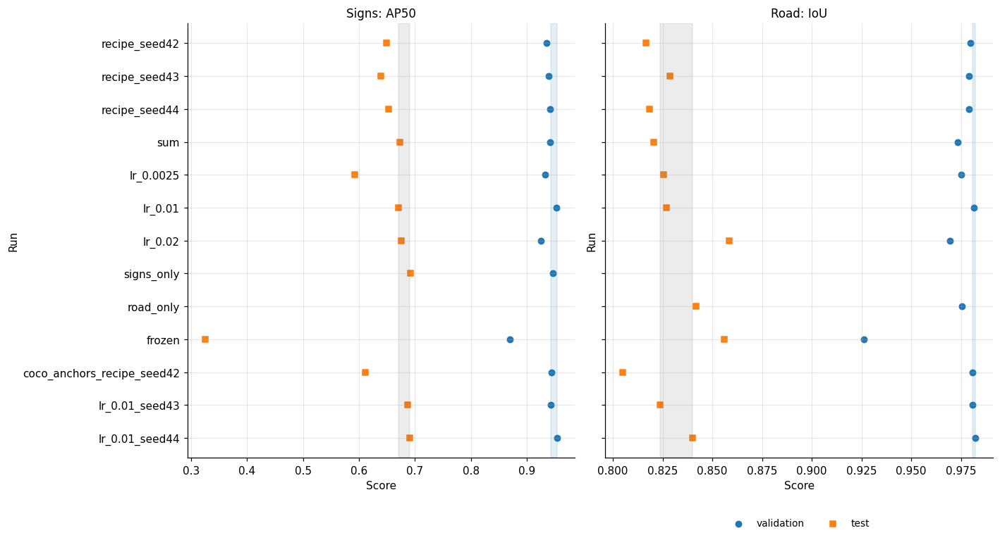

In [31]:
val_scores = validation.rename(columns=lambda name: name.removeprefix("val_"))
table, band = compare_runs({"validation": val_scores, "test": test_scores}, list(final_runs))
fig = plot_runs(table, band)
save_figure(fig, "validation_and_test_runs", "test")
plt.show()

**The gap between the two worlds dwarfs every difference between runs:** for every run the test score (squares) sits far to the left of the validation score (circles), by 0.25 to 0.34 of AP50 (0.54 for the frozen backbone) and 0.07 to 0.18 of road IoU, while most runs differ from each other by a few hundredths. The gray bands are the seed range of the network carried forward on test, AP50 0.671 to 0.690 and road IoU 0.824 to 0.840, and the blue bands the same on validation, so differences between single runs smaller than about 0.02 are inside the noise.

### The final network on every test frame

In [32]:
final = cached_predictions(final_run, test, signs, PREDICTION_DIR / f"{final_name}_test.npz")
final_scores = score_predictions(final, signs)
pd.Series(final_scores).to_frame(f"{final_name}, all {len(test):,} test frames")

,"lr_0.01, all 4,470 test frames"
sign_ap50,0.656
sign_map,0.415
sign_ap75,0.476
sign_ap_small,0.252
sign_ap_medium,0.521
sign_ap_large,0.431
sign_ar100,0.615
road_iou,0.827
miou,0.882
pixel_accuracy,0.952


In [33]:
baseline = road_scores(fixed_mask_counts(prior, test))
final_table = pd.DataFrame({final_name: final_scores, "fixed road mask": baseline})
final_table

,lr_0.01,fixed road mask
sign_ap50,0.656,NaN
sign_map,0.415,NaN
sign_ap75,0.476,NaN
sign_ap_small,0.252,NaN
sign_ap_medium,0.521,NaN
sign_ap_large,0.431,NaN
sign_ar100,0.615,NaN
road_iou,0.827,0.579
miou,0.882,0.704
pixel_accuracy,0.952,0.862


**On all 4,470 test frames the network reaches an AP50 of 0.656 for the signs and a road IoU of 0.827:** the stricter COCO mAP is 0.415, so a good share of the hits fit their sign only loosely, and AP falls from 0.521 for medium signs to 0.252 for small ones. The road is almost never missed (recall 0.993), but about a sixth of what the network calls road is something else (precision 0.832). The fixed road mask scores 0.579 on these frames, so the road head adds 0.248 of IoU over knowing where road usually is, and the pixel accuracy of 0.952 shows again how flattering that score is.

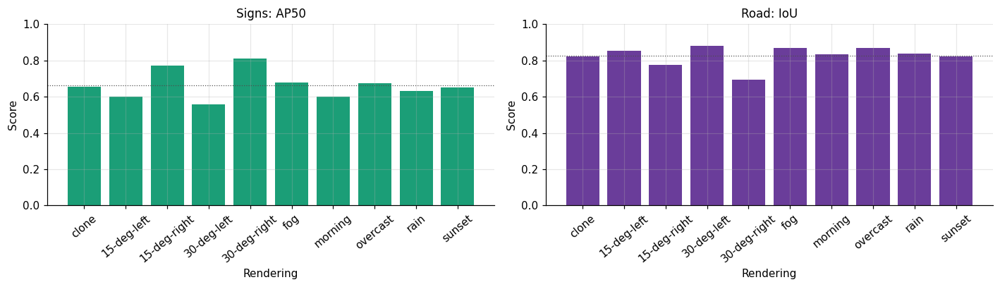

,sign_ap50,sign_map,road_iou,road_precision,road_recall
clone,0.656,0.413,0.820,0.825,0.992
15-deg-left,0.602,0.390,0.854,0.859,0.993
15-deg-right,0.772,0.496,0.774,0.779,0.993
30-deg-left,0.558,0.343,0.881,0.885,0.994
30-deg-right,0.809,0.559,0.693,0.697,0.992
fog,0.678,0.434,0.868,0.873,0.993
morning,0.602,0.370,0.834,0.838,0.994
overcast,0.674,0.422,0.867,0.870,0.995
rain,0.630,0.393,0.839,0.843,0.994
sunset,0.650,0.402,0.823,0.827,0.993


In [34]:
rendering = frames.set_index("frame_id")["variation"]
by_rendering = scores_by_group(final, signs, rendering).loc[list(VARIATIONS)]
fig = plot_group_scores(by_rendering, "Rendering")
save_figure(fig, "scores_by_rendering", "test")
plt.show()
by_rendering[["sign_ap50", "sign_map", "road_iou", "road_precision", "road_recall"]]

**The camera's direction matters far more than the weather:** across the four rotated cameras the sign AP50 ranges from 0.558 (30 degrees left) to 0.809 (30 degrees right) and the road IoU from 0.693 (30 degrees right) to 0.881 (30 degrees left), while the five weather and light renderings stay between 0.602 and 0.678 for the signs and between 0.823 and 0.868 for the road. Turning the camera right brings the signs on that side of the street close and large, which helps the signs, and fills the frame with the paved square beside the street, which hurts the road; turning it left does the opposite. Fog, which removed two thirds of the contrast, costs nothing: its AP50 (0.678) and road IoU (0.868) are among the best, perhaps because it hides the distant clutter that section 11 shows raising false alarms.

### Where a detection counts as a sign

AP scores the whole ranked list, but a driving system has to act on a yes or no, so the frame-level analysis below needs a confidence threshold above which a detection is shown as a sign. It is chosen on the validation frames, as the threshold with the best F1 (the harmonic mean of precision and recall), and the test frames only apply it. Because the threshold turns a confidence into a decision, the cell after it also checks how far the confidence can be read as a probability.

threshold chosen on validation: 0.90


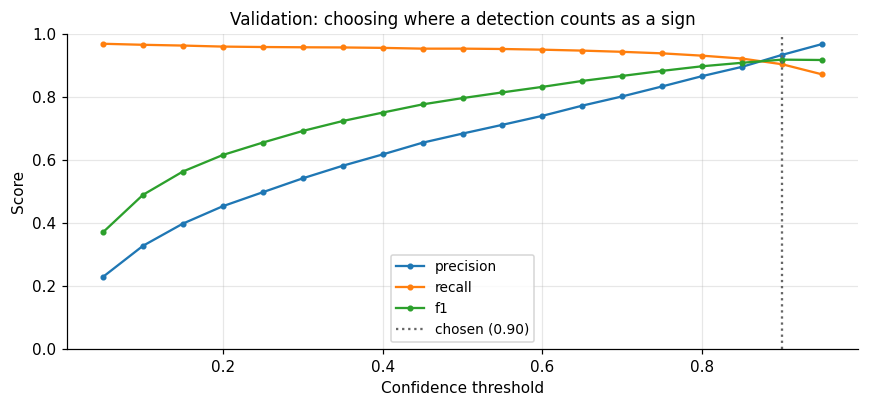

,validation,test
precision,0.934,0.587
recall,0.905,0.777
f1,0.919,0.669


In [35]:
validation_predictions = cached_predictions(
    final_run, val, signs, PREDICTION_DIR / f"{final_name}_validation.npz"
)
sweep = threshold_sweep(validation_predictions, signs)
threshold = sweep.loc[sweep["f1"].idxmax(), "threshold"]
print(f"threshold chosen on validation: {threshold:.2f}")
fig = plot_threshold_sweep(sweep, threshold)
save_figure(fig, "threshold_sweep", "test")
plt.show()
pd.concat(
    {
        "validation": sweep.set_index("threshold").loc[threshold],
        "test": threshold_sweep(final, signs, (threshold,)).set_index("threshold").loc[threshold],
    },
    axis=1,
)

**The threshold chosen on validation is 0.90, and its precision does not survive the test world:** at 0.90 the validation detections have a precision of 0.934 and a recall of 0.905 (F1 0.919). On the test frames the same threshold keeps most of the recall (0.777) but the precision drops to 0.587 (F1 0.669): the detector still finds most signs, and adds false alarms that no validation frame provoked. Section 11 shows what they are.

expected calibration error: 0.171


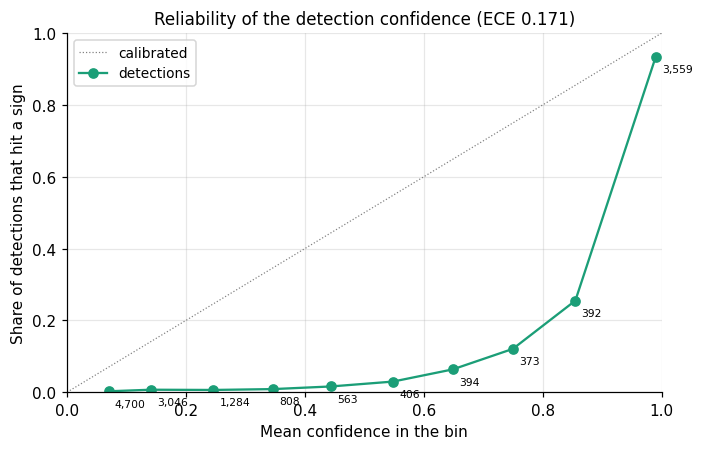

,detections,mean confidence,hit rate
bin,,,
"(-0.001, 0.1]",4700,0.070,0.003
"(0.1, 0.2]",3046,0.141,0.007
"(0.2, 0.3]",1284,0.246,0.006
"(0.3, 0.4]",808,0.347,0.009
"(0.4, 0.5]",563,0.444,0.016
"(0.5, 0.6]",406,0.548,0.030
"(0.6, 0.7]",394,0.649,0.063
"(0.7, 0.8]",373,0.750,0.121
"(0.8, 0.9]",392,0.855,0.255


In [36]:
reliability, error = detection_reliability(validation_predictions, signs)
print(f"expected calibration error: {error:.3f}")
fig = plot_reliability(reliability, error)
save_figure(fig, "reliability", "test")
plt.show()
reliability

**The confidence is not a probability, except near the top:** the expected calibration error is 0.171. Detections are either near-certain or nearly worthless: 3,559 of them have a confidence above 0.9 and 93.4% of those hit a sign, while below 0.5 at most 1.6% do. In between the network is badly overconfident (a mean confidence of 0.855 comes with a hit rate of 25.5%). The chosen threshold of 0.90 lands in the one bin that is close to calibrated, which is why it works on validation. Reading the confidence as a probability, for instance to decide how sure a car must be before it acts on a sign, would first need calibration, such as temperature scaling of the box classifier's scores.

### Which signs are missed

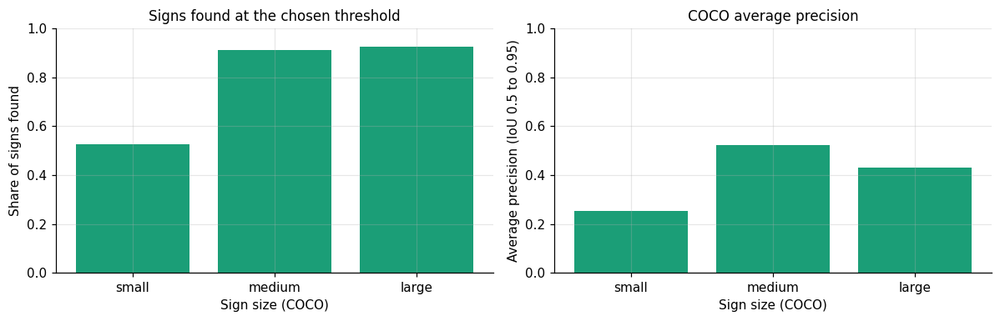

,signs,found,recall,ap
size,,,,
small,1903,1004,0.528,0.252
medium,2656,2424,0.913,0.521
large,779,721,0.926,0.431


signs  found  recall
          at_border                      
at_border False       4873   3733   0.766
          True         465    416   0.895
fragment  False       2674   2081   0.778
          True        2664   2068   0.776

In [37]:
found = sign_outcomes(final, described, threshold)
sizes = size_scores(described, found, final_scores)
fig = plot_size_scores(sizes)
save_figure(fig, "scores_by_sign_size", "test")
plt.show()
display(sizes)
flags = pd.concat({flag: recall_by(described, found, flag) for flag in ("at_border", "fragment")})
flags

**Small signs are where the detector fails:** at the 0.90 threshold it finds 52.8% of the small test signs against 91.3% of the medium and 92.6% of the large ones, and COCO's AP is 0.252, 0.521 and 0.431. Large signs are found as often as medium ones but score a lower AP, so their boxes fit less tightly at COCO's strict IoU levels: the large regions are the ones with long posts and wide boards, whose extent is hardest to match exactly. Signs cut off by the frame's edge are found more often than the rest (89.5% against 76.6%), because they are close and large. **Fragments cost nothing measurable:** half of the test world's sign regions have a neighbor within 3 pixels (2,664 against 2,674 without one), and the network finds them as often as the others (77.6% against 77.8%), so the concern raised in section 4 does not show at this threshold.

### Is the drop about world 0001 or about any unseen world?

Validation and test differ in more than their labels: they are different drives. If the drop from validation to test came from anything that makes world 0001 different, other worlds would hold up when held out; if it came from facing an unseen world at all, every world would drop. The starting recipe was trained twice more with other worlds held out (`HELD_OUT` in `config.py`): on worlds 0001 and 0020 to score 0002 and 0006, and on worlds 0001, 0002 and 0006 to score 0020, both validated on world 0018 as before. Together with the starting recipe's own seed-42 run, which scores worlds 0018 and 0001, every world is scored by a network that never trained on it, all with the same recipe, on one rendering per moment.

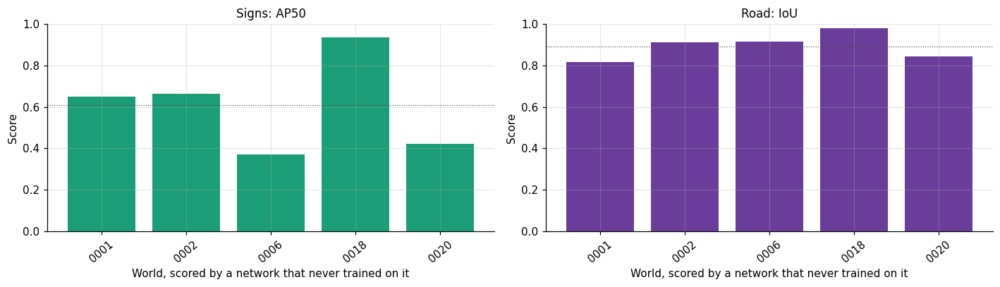

,sign_ap50,sign_map,road_iou,road_precision,road_recall
0001,0.649,0.419,0.817,0.822,0.992
0002,0.665,0.358,0.910,0.994,0.915
0006,0.370,0.240,0.914,0.995,0.918
0018,0.936,0.705,0.980,0.991,0.988
0020,0.421,0.236,0.845,0.857,0.983


In [38]:
world = frames.set_index("frame_id")["world"]
recipe_val = cached_predictions(tuned, val, signs, PREDICTION_DIR / f"{tuned.name}_validation.npz")
val_moments = recipe_val.subset(
    np.isin(recipe_val.frame_ids, one_rendering_per_step(val)["frame_id"])
)
unseen_sets = [predicted[tuned.name], val_moments, *held_out_predictions(frames, signs).values()]
unseen = pd.concat([scores_by_group(p, signs, world) for p in unseen_sets]).sort_index()
fig = plot_group_scores(unseen, "World, scored by a network that never trained on it")
save_figure(fig, "unseen_worlds", "test")
plt.show()
unseen[["sign_ap50", "sign_map", "road_iou", "road_precision", "road_recall"]]

**Every world the network has not seen is hard for the signs; the validation world is the easy exception:** networks that never trained on a world score an AP50 of 0.649 on world 0001, 0.665 on 0002, 0.370 on 0006 and 0.421 on 0020, against 0.936 on the validation world 0018. The drop from validation to test is therefore not about the town: world 0001 sits in the middle of the unseen worlds, and it is the validation world, a quiet road through trees with few large signs, that is unusually easy. The validation score also picked each run's epoch, which makes it slightly optimistic on top of that.

**The road fails in two directions, and the town is the worse case:** on 0002 and 0006 the held-out network calls almost nothing wrongly (precision 0.994 and 0.995) but misses part of the road (recall 0.915 and 0.918), while on 0001 and 0020 it finds nearly all the road (0.992 and 0.983) and calls too much (precision 0.822 and 0.857). The held-out networks trained on fewer worlds than the recipe, and each on a different mix, so the table says which worlds are hard rather than exactly how much.

### What the false road is

The road head almost never misses road on the test world but calls too much road. The cell below runs the final network over the validation and test moments again and sorts every pixel it calls road by what the pixel really is.

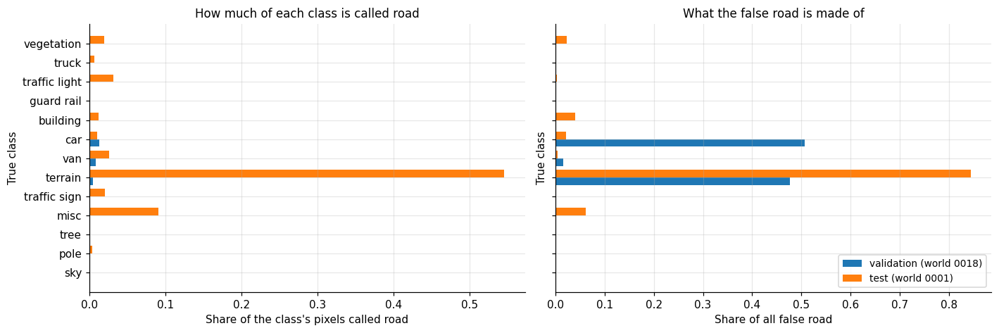

validation (world 0018)                                \
                               pixels called road share called road   
true class                                                            
building                            0           0               NaN   
car                           9318805      125361             0.013   
guard rail                          0           0               NaN   
misc                            32159           1             0.000   
pole                           131949           0             0.000   
road                         30349468    30025711             0.989   
sky                          10056929           0             0.000   
terrain                      23937842      118146             0.005   
traffic light                       0           0               NaN   
traffic sign                  1597660          60             0.000   
tree                         81544106         133             0.000   
truck                               0           0               NaN   
van                            448866        3838             0.009   
vegetation                          0           0               NaN   

                                  test (world 0001)              \
              share of false road            pixels called road   
true class                                                        
building                    0.000          30972418      386423   
car                         0.506          19812258      206470   
guard rail                  0.000                 0           0   
misc                        0.000           6611753      603274   
pole                        0.000            726478        2643   
road                          NaN          48423250    48108980   
sky                         0.000          28472515         100   
terrain                     0.477          15058195     8220924   
traffic light               0.000            895281       28254   
traffic sign                0.000            674521       13929   
tree                        0.001          41020496        4047   
truck                       0.000            864062        5976   
van                         0.016           1780728       46752   
vegetation                  0.000          11813686      226465   

                                                     
              share called road share of false road  
true class                                           
building                  0.012               0.040  
car                       0.010               0.021  
guard rail                  NaN               0.000  
misc                      0.091               0.062  
pole                      0.004               0.000  
road                      0.994                 NaN  
sky                       0.000               0.000  
terrain                   0.546               0.844  
traffic light             0.032               0.003  
traffic sign              0.021               0.001  
tree                      0.000               0.000  
truck                     0.007               0.001  
van                       0.026               0.005  
vegetation                0.019               0.023

In [39]:
calls = {
    f"validation (world {PARTITIONS['validation'][0]})": cached_road_calls(
        final_run, one_rendering_per_step(val), signs, ROAD_CALL_DIR / "validation.csv"
    ),
    f"test (world {PARTITIONS['test'][0]})": cached_road_calls(
        final_run, test_moments, signs, ROAD_CALL_DIR / "test.csv"
    ),
}
fig = plot_road_calls(calls)
save_figure(fig, "false_road", "test")
plt.show()
pd.concat(calls, axis=1)

**The false road is terrain, and in the town that means pavement:** on the test moments the network calls 54.6% of the terrain pixels road, and terrain makes up 84.4% of all the false road; `misc` (6.2%) and buildings (4.0%) follow far behind. On validation the little false road there is splits between cars (50.6%) and terrain (47.7%). The frames of section 11 show what the town's terrain is: the sidewalks between parked cars and buildings and a large paved square beside the street, flat gray surfaces that look like road. The training worlds have terrain too, but as grass and embankments, so nothing taught the road head that a paved surface beside the street is not road; what separates them in the town is a curb and the context, not the texture.

### What one pass saves

Latency is measured one frame at a time, from the tensor in memory to the boxes and the road probabilities, as the median over 100 test frames after 10 untimed ones, for the two-headed network and for the two single-task networks that would otherwise run side by side.

In [40]:
images = timing_images(test)
networks = [final_name, "signs_only", "road_only"]
timings = pd.DataFrame(
    {name: time_per_frame(load_model(runs[name]), images) for name in networks}
).T
pair = timings.loc[["signs_only", "road_only"], "median_ms"].sum()
print(f"two single-task networks in sequence: {pair:.1f} ms per frame")
timings

two single-task networks in sequence: 38.4 ms per frame


,frames,median_ms,p95_ms
lr_0.01,100.000,24.927,25.733
signs_only,100.000,22.795,23.822
road_only,100.000,15.571,16.054


**One pass saves a third of the time of two networks:** the two-headed network takes a median 25.3 ms per frame on the RTX 3090, against 22.9 ms for the signs-only network and 15.6 ms for the road-only network, 38.4 ms when they run in sequence. Sharing the backbone saves 13.1 ms per frame, and adding the road head to the detector costs 2.4 ms, so at about 40 frames per second the network keeps up with a 30-frame-per-second camera with room to spare.

## 11. Best and worst frames

Every test frame is scored on its own at the threshold chosen on validation: its road IoU, and for its signs the F1 of found signs against misses and false alarms. The combined score is the mean of the two, defined for frames that have a sign or a false alarm. The three best and three worst frames by each score are drawn below with the network's calls: road found in purple, false road in pink, road missed in orange; signs found as green boxes, signs missed as dashed orange boxes, false alarms in pink.

In [41]:
per_frame = frame_scores(final, signs, threshold).merge(
    frames[["frame_id", "file", "variation", "step"]], on="frame_id"
)
network = load_model(final_run)
per_frame[["road_iou", "sign_f1", "combined"]].describe()

,road_iou,sign_f1,combined
count,4470.000,3538.000,3538.000
mean,0.823,0.537,0.694
std,0.153,0.417,0.242
min,0.291,0.000,0.151
25%,0.744,0.000,0.452
50%,0.880,0.667,0.776
75%,0.942,1.000,0.906
max,0.990,1.000,0.994


**Most frames are good, and the bad ones are very bad:** the median test frame has a road IoU of 0.880 and a sign F1 of 0.667, but a quarter of the 3,538 frames with a sign or a false alarm score a sign F1 of 0, and the worst road IoU is 0.291.

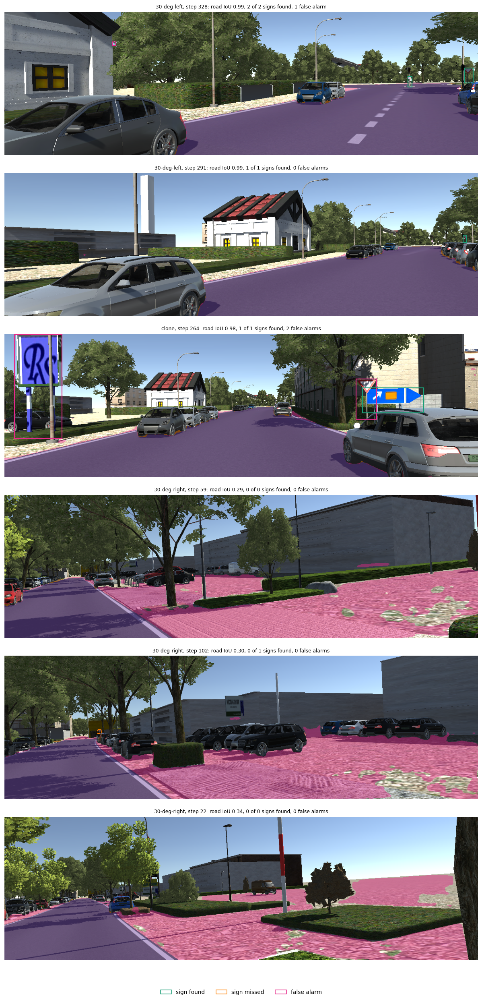

In [42]:
chosen = extreme_frames(per_frame, "road_iou", EXTREME_COUNT)
fig = frame_panels(prediction_panels(network, chosen, signs, threshold, frame_titles(chosen)))
save_figure(fig, "best_and_worst_road", "frames")
plt.show()

**The worst road frames all look across the same paved square:** the three best frames (road IoU 0.98 to 0.99) look along the street with grass or gravel beside it, and they also show the detector finding small, distant signs. The three worst (0.29 to 0.34) come from the camera turned 30 degrees right, looking across a large paved square and car park next to the street, which the labels call terrain and the network calls road almost entirely. That is as much a question about the label as an error: the square is paved and cars park on it, and only a curb and the buildings around it say it is not part of the street. The third-best frame also shows a false alarm on a billboard and a second one on a yield sign that the label merges with the direction board beside it into a single region.

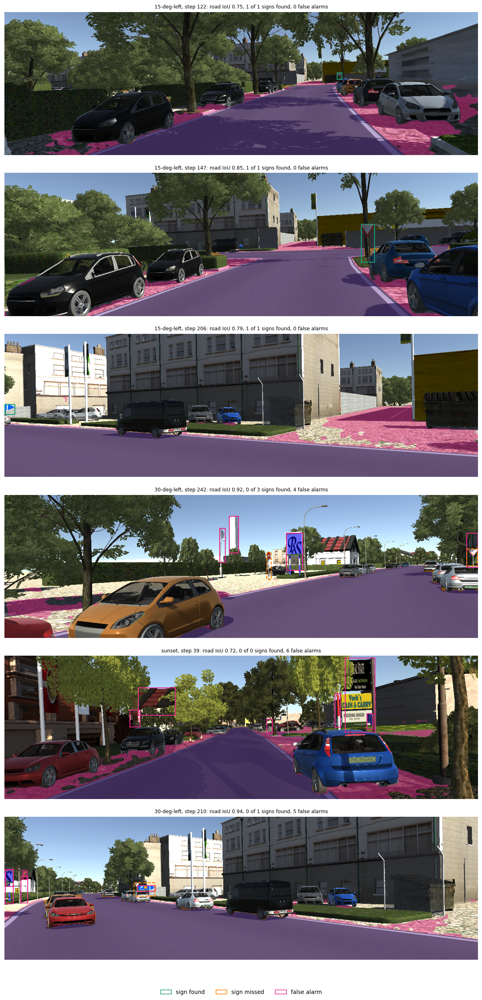

In [43]:
chosen = extreme_frames(per_frame, "sign_f1", EXTREME_COUNT)
fig = frame_panels(prediction_panels(network, chosen, signs, threshold, frame_titles(chosen)))
save_figure(fig, "best_and_worst_signs", "frames")
plt.show()

**False alarms on shop signs and billboards dominate the worst sign frames:** the best frames each find their one sign, from a yield sign on its post to a small sign at the frame's edge, with no false alarm. The worst have no sign found and four to six false alarms each, on advertising boards, shop signs, a white chimney, a roof and a lamp post. The town is the only world with such panels, so the network was never shown that a board with text on a post can be something other than a traffic sign. Some of the misses are matching rather than blindness: in step 210 the network boxes the blue direction board, but the label's region also takes in what hangs below it, and in step 242 the box on the sign at the frame's right edge also takes in the panel above it. Both boxes overlap their label by less than the IoU of 0.5 a hit needs, so each counts as a miss and a false alarm at once.

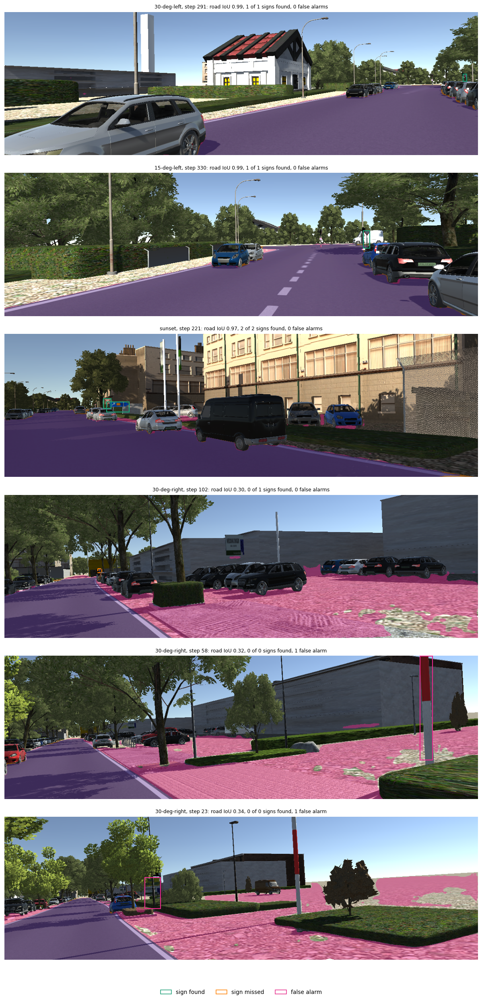

In [44]:
chosen = extreme_frames(per_frame, "combined", EXTREME_COUNT)
fig = frame_panels(prediction_panels(network, chosen, signs, threshold, frame_titles(chosen)))
save_figure(fig, "best_and_worst_combined", "frames")
plt.show()

**The best frames look along an open street, the worst across the square:** the three best (road IoU 0.97 to 0.99, every sign found, one of them at sunset) look down the street with its signs near the vanishing point. The three worst again face the paved square of the right-turned camera, and two of them add a false alarm on a striped post or a dark board.

In [45]:
worst = per_frame.nsmallest(round(len(per_frame) * WORST_SHARE), "combined")
worst_renderings = (
    pd.concat(
        {
            "worst frames": worst["variation"].value_counts(normalize=True),
            "all frames": per_frame["variation"].value_counts(normalize=True),
        },
        axis=1,
    )
    .loc[list(VARIATIONS)]
    .fillna(0)
)
worst_renderings

,worst frames,all frames
variation,,
clone,0.121,0.100
15-deg-left,0.103,0.100
15-deg-right,0.125,0.100
30-deg-left,0.000,0.100
30-deg-right,0.246,0.100
fog,0.027,0.100
morning,0.085,0.100
overcast,0.049,0.100
rain,0.067,0.100


**The worst frames come from one camera angle and from sunset:** the camera turned 30 degrees right supplies 24.6% of the worst 5% of test frames by combined score, against its 10% of all frames, and sunset 17.9%, while fog (2.7%), overcast (4.9%) and the camera turned 30 degrees left (none) are underrepresented. What the camera points at matters more than the weather, and among the weather renderings the low light of sunset costs the most frames.

## 12. Conclusion, limitations and recommendations

### Conclusion

**One network detects the signs and draws the road in a single 25 ms pass, and on a driving world it never saw it reaches a sign AP50 of 0.656 and a road IoU of 0.827:** a Faster R-CNN with a ResNet-50 feature pyramid and COCO weights carries a second head, the semantic branch of Panoptic FPN, on the same pyramid. It trains in two stages, heads first and then the backbone, with each task's gradient into the backbone scaled so that both pull with the same strength, and a learning rate of 0.01 in stage two replaced the starting 0.005 by the rule fixed before the runs. Over three seeds the same network scores an AP50 of 0.671 to 0.690 and a road IoU of 0.824 to 0.840 on the test moments.

**What decided the results:**

- **The world mattered more than any choice of network:** every run loses 0.25 to 0.34 of AP50 and 0.07 to 0.18 of road IoU from validation to test, while the runs differ from each other by a few hundredths. Networks tested on other unseen worlds score between 0.370 and 0.665 AP50, so it is the validation world that is unusually easy, not the test world that is unusually hard for the signs.
- **The town's pavement is what the road head calls road:** 84.4% of the false road is terrain, the sidewalks and a paved square that the training worlds never showed, and the worst road frames (IoU 0.29 to 0.34) all look across that square.
- **Panels that are not traffic signs cause the false alarms:** at the threshold chosen on validation, precision falls from 0.934 to 0.587 on the test world, and the worst frames show shop signs and billboards boxed as signs.
- **Small signs are found half the time:** recall is 52.8% for small signs against 91.3% and 92.6% for medium and large ones.
- **Equal training is a trade between the tasks:** balancing the gradients lifts the road and lowers the signs relative to the plain sum, at the same validation score (0.958). On the test world each task alone beats the shared network (AP50 0.692 against 0.649, road IoU 0.842 against 0.817), while the single pass saves 13.1 ms per frame against running the two.
- **Fine-tuning the backbone pays on validation and costs the road on the town:** it is worth 6.7 points of AP50 and 5.4 of road IoU on validation, yet the frozen backbone's road transfers best to the test world (0.856).

### Limitations

- **Synthetic frames:** Virtual KITTI is rendered, with clean geometry, perfect labels and no sensor noise, so these scores do not transfer to real camera footage as they are.
- **Five worlds:** one world validates and one tests, and the validation world turned out to be unusually easy, so validation rankings and the confidence threshold transfer only partly. The held-out networks trained on different mixes of worlds, which makes their comparison qualitative.
- **The label's notion of a sign:** a region includes its post and merges touching panels, so a box that fits the panel alone can miss the 0.5 IoU a hit needs, and the scores partly measure agreement with this convention.
- **Comparisons at the starting learning rate:** the balancing, the anchors, the single-task baselines and the frozen backbone were each measured against the recipe at 0.005. Their effect at the carried-forward 0.01 is untested, and so is the combination of the two candidates that passed the rule.
- **One seed for most variants:** only the recipe and the carried-forward network ran with three seeds, so single-run differences under about 0.02 are inside the noise.
- **Uncalibrated confidence:** the expected calibration error is 0.171, so the confidence ranks detections well but cannot be read as a probability.
- **Latency on one GPU:** 25.3 ms is the median for one frame at a time on an RTX 3090 in 32-bit floats, without half precision or a deployment runtime.

### Recommendations

- **Choose settings on a world that looks like deployment:** rotate which world validates (cross-world validation) or validate on a town-like world, so the epoch, the learning rate and the threshold are chosen where the network will struggle.
- **Show the network a town:** add urban scenes with sidewalks, squares, shop signs and billboards, from real data such as KITTI or Cityscapes or from a driving simulator such as CARLA, so pavement and advertising stop being unseen classes.
- **Fit the backbone less to the training worlds:** the frozen backbone's road transferred best, so try a lower learning rate for the backbone than for the heads, or fewer fine-tuned stages, and judge it on held-out worlds.
- **Give small signs more pixels:** feed the frames at twice their size, or add a finer pyramid level with smaller anchors, since half of the small signs are missed.
- **Calibrate before acting on the confidence:** fit a temperature on validation detections and check the reliability again.
- **Test the other ways of weighting the tasks:** uncertainty weighting (Kendall et al. 2018) or GradNorm proper, and the balancing at the carried-forward learning rate, against the single-task networks on the held-out worlds.

In [46]:
tables = {
    "worlds": group_summary(frames, "world").reset_index(),
    "partitions": group_summary(partitioned, "partition").reset_index(),
    "sign_regions": sign_summary(described).rename_axis("measure").reset_index(name="value"),
    "anchor_coverage": anchor_coverage(boxes, ANCHOR_CANDIDATES, ANCHOR_IOU_LEVELS)
    .rename_axis("anchor_set")
    .reset_index(),
    "rendering_agreement": agreement.reset_index(),
    "frame_repetition": repetition,
    "mask_ceilings": ceilings,
    "parameters": parameters.rename_axis("part").reset_index(),
    "training_history": history.reset_index(),
    "pulls": pulls,
    "validation_runs": validation.rename_axis("run").reset_index(),
    "test_runs": test_scores.rename_axis("run").reset_index(),
    "final_test_scores": final_table.rename_axis("score").reset_index(),
    "variant_verdicts": verdicts.rename_axis("run").reset_index(),
    "sign_recall_by_flag": flags.rename_axis(["flag", "value"]).reset_index(),
    "worst_frame_renderings": worst_renderings.rename_axis("rendering").reset_index(),
    "scores_by_rendering": by_rendering.rename_axis("rendering").reset_index(),
    "threshold_sweep": sweep,
    "reliability": reliability.reset_index().astype({"bin": str}),
    "sign_sizes": sizes.rename_axis("size").reset_index(),
    "unseen_worlds": unseen.rename_axis("world").reset_index(),
    "road_calls": pd.concat(calls, names=["frames"]).reset_index(),
    "latency": timings.rename_axis("network").reset_index(),
    "frame_scores": per_frame.drop(columns="file"),
}
print(write_processed(tables))

['anchor_coverage.csv', 'final_test_scores.csv', 'frame_repetition.csv', 'frame_scores.csv', 'latency.csv', 'mask_ceilings.csv', 'parameters.csv', 'partitions.csv', 'pulls.csv', 'reliability.csv', 'rendering_agreement.csv', 'road_calls.csv', 'scores_by_rendering.csv', 'sign_recall_by_flag.csv', 'sign_regions.csv', 'sign_sizes.csv', 'test_runs.csv', 'threshold_sweep.csv', 'training_history.csv', 'unseen_worlds.csv', 'validation_runs.csv', 'variant_verdicts.csv', 'worlds.csv', 'worst_frame_renderings.csv']


Every file in `data/processed/` is written by the cell above, so none of them can drift from what this notebook shows.